In [1]:
# Cell 1: Google Drive mount only
# Mounts Google Drive for Colab access to the project files.
# Produces the Drive filesystem mount used by later path configuration.

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
# Cell 2: Imports, global analysis configuration, paths, filenames, and shared constants
# Imports dependencies and defines analysis constants, project paths, filenames, and output locations.
# Produces the shared configuration values used by the canonical handoff and downstream analysis.

from pathlib import Path
import hashlib
import json
import os
import subprocess
import sys
import uuid
import warnings
import shutil

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import trange

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

SYSTEM_NAME = "Viruses"
SYSTEM_PREFIX = "viruses"
MIN_GROUP_N = 10
N_BOOT = 1000
RANDOM_SEED = 42
GROUP_COL = "group"
ANALYSIS_YEAR = None
PRIMARY_P_DEFINITION = None
OUTPUT_SUFFIX = ""
EXPECTED_CANONICAL_ROWS = 268
RUN_BAYESIAN = True
BAYES_MODELS_TO_RUN = None
BAYES_FORCE_RERUN = False

BAYES_CHAINS = 4
BAYES_DRAWS = 2000
BAYES_TUNE = 1000

BAYES_TARGET_ACCEPT_HIERARCHICAL = 0.95
BAYES_MAX_TREEDEPTH_HIERARCHICAL = 12

BAYES_RHAT_THRESHOLD = 1.01
BAYES_PRIOR_PREDICTIVE_DRAWS = 500
BAYES_PRIOR_LOCATION_SD = 2.0
BAYES_PRIOR_LOG_SCALE_SD = 1.0
BAYES_PRIOR_FISHER_RHO_SD = 1.5
BAYES_PRIOR_GROUP_LOCATION_SD = 1.0
BAYES_PRIOR_GROUP_LOG_SCALE_SD = 0.75
BAYES_PRIOR_GROUP_FISHER_RHO_SD = 1.0
BAYES_PRIOR_WIDTH_MULTIPLIER = 1.0

SAVE_BAYESIAN_DRAWS = False

SLOPE_REFERENCE_VALUES = {
    "MA": 1.0,
    "PT": 1.0,
    "reqq": 0.0,
    "reqz": 0.0,
    "MAxPT": 1.0,
}


np.random.seed(RANDOM_SEED)

DRIVE_ROOT = Path("/content/drive/MyDrive")
LEGACY_PROJECT_ROOT = DRIVE_ROOT / "Hopeful Monsters" / "Projects" / "Mass Action 2025"
PROJECT_ROOT = DRIVE_ROOT / "Hopeful Monsters" / "Projects" / "Mass Action 2026"
LEGACY_DATA_DIR = LEGACY_PROJECT_ROOT / "Datasets" / "Viruses"
DATA_DIR = PROJECT_ROOT / "Datasets" / "Viruses"
DATASETS_DIR = DATA_DIR / "datasets"
INPUT_DIR = DATASETS_DIR / "input"
CANONICAL_DIR = DATASETS_DIR / "canonical"
QC_DIR = DATA_DIR / "qc"
RESULTS_DIR = DATA_DIR / "results"
RESULT_TABLE_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"
WORKING_DIR = DATA_DIR / "working"
BASE_DIR = DATA_DIR
CODE_DIR = PROJECT_ROOT / "Code"
BAYESIAN_CHECKPOINT_DIR = WORKING_DIR / "bayesian_checkpoints"

INPUT_FILENAME = "Wilhelm data BK 20250915 finalised.csv"
LEGACY_INPUT_PATH = LEGACY_DATA_DIR / INPUT_FILENAME
INPUT_PATH = INPUT_DIR / INPUT_FILENAME
NOTEBOOK_FILENAME = "viruses_mass_action_bayes_20260901.ipynb"
NOTEBOOK_PATH = CODE_DIR / NOTEBOOK_FILENAME
NOTEBOOK_STEM = Path(NOTEBOOK_FILENAME).stem
PY_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.py"
MD_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.md"
TXT_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.txt"
PY_EXPORT_PATH = CODE_DIR / PY_EXPORT_FILENAME
MD_EXPORT_PATH = CODE_DIR / MD_EXPORT_FILENAME
TXT_EXPORT_PATH = CODE_DIR / TXT_EXPORT_FILENAME

CANONICAL_REQUIRED_COLUMNS = ["obs_id", "system", "group", "N", "P", "R"]
CANONICAL_HANDOFF_FILENAME = f"{SYSTEM_PREFIX}_canonical{OUTPUT_SUFFIX}.csv"
CANONICAL_QC_FILENAME = f"{SYSTEM_PREFIX}_canonical_qc{OUTPUT_SUFFIX}.csv"
CONSTRUCTION_QC_FILENAME = f"{SYSTEM_PREFIX}_constructed_npr_qc{OUTPUT_SUFFIX}.csv"
REJECTED_NPR_FILENAME = f"{SYSTEM_PREFIX}_rejected_npr{OUTPUT_SUFFIX}.csv"
MIGRATION_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_input_migration_manifest.csv"
GROUP_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_group_counts_raw{OUTPUT_SUFFIX}.csv"
GROUP_ELIGIBILITY_FILENAME = f"{SYSTEM_PREFIX}_group_eligibility{OUTPUT_SUFFIX}.csv"
GROUP_RANGES_FILENAME = f"{SYSTEM_PREFIX}_group_ranges{OUTPUT_SUFFIX}.csv"
VALID_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_valid_counts_by_model{OUTPUT_SUFFIX}.csv"
ELIGIBLE_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_eligible_group_counts_by_model{OUTPUT_SUFFIX}.csv"
ANALYSIS_QC_FILENAME = f"{SYSTEM_PREFIX}_analysis_qc{OUTPUT_SUFFIX}.csv"
GLOBAL_FITS_FILENAME = f"{SYSTEM_PREFIX}_global_fits{OUTPUT_SUFFIX}.csv"
GROUP_FITS_FILENAME = f"{SYSTEM_PREFIX}_group_fits{OUTPUT_SUFFIX}.csv"
FIT_SUMMARY_FILENAME = f"{SYSTEM_PREFIX}_fit_summary{OUTPUT_SUFFIX}.csv"
DISPLAYED_STATS_FILENAME = f"{SYSTEM_PREFIX}_displayed_line_stats{OUTPUT_SUFFIX}.csv"
PLOT_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_plot_manifest{OUTPUT_SUFFIX}.csv"
OUTPUT_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_output_manifest{OUTPUT_SUFFIX}.csv"

BAYESIAN_LINE_STATS_FILENAME = f"{SYSTEM_PREFIX}_bayesian_sma_line_stats{OUTPUT_SUFFIX}.csv"
BAYESIAN_MODEL_DIAGNOSTICS_FILENAME = f"{SYSTEM_PREFIX}_bayesian_sma_model_diagnostics{OUTPUT_SUFFIX}.csv"

PLOT_MA_FILENAME = f"{SYSTEM_PREFIX}_global_log10R_vs_log10MA{OUTPUT_SUFFIX}.pdf"
PLOT_PT_FILENAME = f"{SYSTEM_PREFIX}_global_log10R_vs_log10PT{OUTPUT_SUFFIX}.pdf"
PLOT_REQQ_FILENAME = f"{SYSTEM_PREFIX}_global_log10MA_vs_log10reqq{OUTPUT_SUFFIX}.pdf"
PLOT_REQZ_FILENAME = f"{SYSTEM_PREFIX}_global_log10PT_vs_log10reqz{OUTPUT_SUFFIX}.pdf"
PLOT_MAPT_FILENAME = f"{SYSTEM_PREFIX}_log10PT_vs_log10MA{OUTPUT_SUFFIX}.pdf"
FOREST_MA_PT_MERGED_FILENAME = f"{SYSTEM_PREFIX}_forest_MA_PT_merged{OUTPUT_SUFFIX}.pdf"
FOREST_REQQ_REQZ_MERGED_FILENAME = f"{SYSTEM_PREFIX}_forest_reqq_reqz_merged{OUTPUT_SUFFIX}.pdf"
FOREST_CROSSOVER_FILENAME = f"{SYSTEM_PREFIX}_forest_crossover{OUTPUT_SUFFIX}.pdf"

CANONICAL_HANDOFF_PATH = CANONICAL_DIR / CANONICAL_HANDOFF_FILENAME
CANONICAL_QC_PATH = QC_DIR / CANONICAL_QC_FILENAME
CONSTRUCTION_QC_PATH = QC_DIR / CONSTRUCTION_QC_FILENAME
REJECTED_NPR_PATH = QC_DIR / REJECTED_NPR_FILENAME
MIGRATION_MANIFEST_PATH = QC_DIR / MIGRATION_MANIFEST_FILENAME
GROUP_COUNTS_PATH = QC_DIR / GROUP_COUNTS_FILENAME
GROUP_ELIGIBILITY_PATH = QC_DIR / GROUP_ELIGIBILITY_FILENAME
GROUP_RANGES_PATH = QC_DIR / GROUP_RANGES_FILENAME
VALID_COUNTS_PATH = QC_DIR / VALID_COUNTS_FILENAME
ELIGIBLE_COUNTS_PATH = QC_DIR / ELIGIBLE_COUNTS_FILENAME
ANALYSIS_QC_PATH = QC_DIR / ANALYSIS_QC_FILENAME
GLOBAL_FITS_PATH = RESULT_TABLE_DIR / GLOBAL_FITS_FILENAME
GROUP_FITS_PATH = RESULT_TABLE_DIR / GROUP_FITS_FILENAME
FIT_SUMMARY_PATH = RESULT_TABLE_DIR / FIT_SUMMARY_FILENAME
DISPLAYED_STATS_PATH = RESULT_TABLE_DIR / DISPLAYED_STATS_FILENAME
PLOT_MANIFEST_PATH = QC_DIR / PLOT_MANIFEST_FILENAME
OUTPUT_MANIFEST_PATH = QC_DIR / OUTPUT_MANIFEST_FILENAME

BAYESIAN_LINE_STATS_PATH = RESULT_TABLE_DIR / BAYESIAN_LINE_STATS_FILENAME
BAYESIAN_MODEL_DIAGNOSTICS_PATH = QC_DIR / BAYESIAN_MODEL_DIAGNOSTICS_FILENAME

PLOT_MA_PATH = FIG_DIR / PLOT_MA_FILENAME
PLOT_PT_PATH = FIG_DIR / PLOT_PT_FILENAME
PLOT_REQQ_PATH = FIG_DIR / PLOT_REQQ_FILENAME
PLOT_REQZ_PATH = FIG_DIR / PLOT_REQZ_FILENAME
PLOT_MAPT_PATH = FIG_DIR / PLOT_MAPT_FILENAME
FOREST_MA_PT_MERGED_PATH = FIG_DIR / FOREST_MA_PT_MERGED_FILENAME
FOREST_REQQ_REQZ_MERGED_PATH = FIG_DIR / FOREST_REQQ_REQZ_MERGED_FILENAME
FOREST_CROSSOVER_PATH = FIG_DIR / FOREST_CROSSOVER_FILENAME



for path in [CODE_DIR, INPUT_DIR, CANONICAL_DIR, QC_DIR, RESULT_TABLE_DIR, FIG_DIR, WORKING_DIR, BAYESIAN_CHECKPOINT_DIR]:
    path.mkdir(parents=True, exist_ok=True)


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def copy_verified_input(source, destination):
    """Copy a 2025 input into 2026 once; never overwrite a different file."""
    source = Path(source)
    destination = Path(destination)
    try:
        source.relative_to(LEGACY_PROJECT_ROOT)
        destination.relative_to(PROJECT_ROOT)
    except ValueError as exc:
        raise RuntimeError("Input migration must flow only from Mass Action 2025 to Mass Action 2026") from exc
    if not source.is_file():
        raise FileNotFoundError(f"Legacy source input not found: {source}")
    destination.parent.mkdir(parents=True, exist_ok=True)
    source_hash = sha256_file(source)
    if destination.exists():
        if not destination.is_file() or sha256_file(destination) != source_hash:
            raise RuntimeError(f"Refusing to overwrite non-identical 2026 input: {destination}")
        status = "verified_existing"
    else:
        partial = destination.with_name(f".{destination.name}.partial")
        if partial.exists():
            partial.unlink()
        shutil.copy2(source, partial)
        if sha256_file(partial) != source_hash:
            raise IOError(f"Copied input failed SHA-256 verification: {source}")
        os.replace(partial, destination)
        status = "copied"
    return {
        "source_2025": str(source),
        "destination_2026": str(destination),
        "size_bytes": int(source.stat().st_size),
        "sha256": source_hash,
        "status": status,
    }


# Idempotent first-run setup: subsequent runs verify the same 2026 copy.
migration_manifest = pd.DataFrame([
    copy_verified_input(LEGACY_INPUT_PATH, INPUT_PATH),
])
migration_manifest.to_csv(MIGRATION_MANIFEST_PATH, index=False)

print("Configuration loaded")
print(f"SYSTEM_NAME: {SYSTEM_NAME}")
print(f"SYSTEM_PREFIX: {SYSTEM_PREFIX}")
print(f"MIN_GROUP_N: {MIN_GROUP_N}")
print(f"N_BOOT: {N_BOOT}")
print(f"RANDOM_SEED: {RANDOM_SEED}")
print(f"LEGACY_PROJECT_ROOT (read-only): {LEGACY_PROJECT_ROOT}")
print(f"PROJECT_ROOT (active): {PROJECT_ROOT}")
print(f"DATA_DIR: {DATA_DIR}")
print(f"INPUT_DIR: {INPUT_DIR}")
print(f"CANONICAL_DIR: {CANONICAL_DIR}")
print(f"QC_DIR: {QC_DIR}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"FIG_DIR: {FIG_DIR}")
print(f"BAYESIAN_CHECKPOINT_DIR: {BAYESIAN_CHECKPOINT_DIR}")


Configuration loaded
SYSTEM_NAME: Viruses
SYSTEM_PREFIX: viruses
MIN_GROUP_N: 10
N_BOOT: 1000
RANDOM_SEED: 42
LEGACY_PROJECT_ROOT (read-only): /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2025
PROJECT_ROOT (active): /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026
DATA_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses
INPUT_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/datasets/input
CANONICAL_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/datasets/canonical
QC_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/qc
RESULTS_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results
FIG_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures
BAYESIAN_CHECKPOINT_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mas

In [3]:
# Cell 3: Shared helper functions for I/O, QC, and display
# Defines shared I/O, display, assertion, QC, and regression helper utilities.
# Produces reusable functions called by preprocessing and shared analysis cells.

def ensure_dir(path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def print_header(title, width=72):
    print("\n" + "=" * width)
    print(title)
    print("=" * width)


def display_df(obj):
    if "display" in globals():
        display(obj)
    else:
        print(obj)


def load_csv(path, **kwargs):
    path = Path(path)
    df = pd.read_csv(path, **kwargs)
    print(f"Loaded {path}: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
    return df


def save_csv(df, path, index=False):
    path = Path(path)
    ensure_dir(path.parent)
    df.to_csv(path, index=index)
    print(f"Saved table: {path}")


def save_figure(fig, path, dpi=300, close=False, show=True):
    path = Path(path)
    ensure_dir(path.parent)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved figure: {path}")
    if show:
        plt.show()
    if close:
        plt.close(fig)


def check_required_columns(df, required_cols, df_name="dataframe"):
    missing = [col for col in required_cols if col not in df.columns]
    if missing:
        raise ValueError(f"{df_name} is missing required columns: {missing}")
    print(f"All required columns present in {df_name}: {required_cols}")


def assert_path_exists(path, description="path"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{description} not found: {path}")
    print(f"Found {description}: {path}")


def summarize_numeric(df, cols):
    rows = []
    for col in cols:
        if col not in df.columns:
            continue
        values = pd.to_numeric(df[col], errors="coerce")
        rows.append({
            "column": col,
            "nonmissing": int(values.notna().sum()),
            "min": float(values.min()) if values.notna().any() else np.nan,
            "median": float(values.median()) if values.notna().any() else np.nan,
            "max": float(values.max()) if values.notna().any() else np.nan,
        })
    return pd.DataFrame(rows)


def summarize_text(df, cols, n_examples=10):
    out = {}
    for col in cols:
        if col not in df.columns:
            continue
        values = df[col].dropna().astype(str).str.strip()
        unique_values = values[values != ""].unique().tolist()
        out[col] = unique_values[:n_examples]
    return out


def count_complete_rows(df, cols):
    check_required_columns(df, cols, df_name="complete-row check input")
    return int(df[cols].notna().all(axis=1).sum())


def count_positive_complete_rows(df, cols):
    check_required_columns(df, cols, df_name="positive-row check input")
    mask = pd.Series(True, index=df.index)
    for col in cols:
        values = pd.to_numeric(df[col], errors="coerce")
        mask &= values.notna() & values.gt(0)
    return int(mask.sum())


def value_counts_table(df, col):
    if col not in df.columns:
        return pd.DataFrame(columns=[col, "n"])
    return (
        df[col]
        .fillna("MISSING")
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="n")
    )


def canonical_handoff_qc(df, expected_rows=None, expected_group_count=None, label="canonical"):
    print_header("CANONICAL HANDOFF QC")
    check_required_columns(df, CANONICAL_REQUIRED_COLUMNS, df_name=label)

    numeric_status = {}
    for col in ["N", "P", "R"]:
        converted = pd.to_numeric(df[col], errors="coerce")
        numeric_status[col] = {
            "nonmissing_before": int(df[col].notna().sum()),
            "numeric_after": int(converted.notna().sum()),
        }
        if int(df[col].notna().sum()) != int(converted.notna().sum()):
            raise ValueError(f"{label}.{col} contains non-numeric non-missing values")

    complete_npr = count_complete_rows(df, ["N", "P", "R"])
    positive_npr = count_positive_complete_rows(df, ["N", "P", "R"])
    group_count = int(df["group"].nunique(dropna=True))

    if expected_rows is not None and len(df) != expected_rows:
        raise RuntimeError(
            f"{label} row-count check failed: expected {expected_rows:,}, found {len(df):,}"
        )

    if expected_group_count is not None and group_count != expected_group_count:
        raise RuntimeError(
            f"{label} group-count check failed: expected {expected_group_count:,}, found {group_count:,}"
        )

    qc = pd.DataFrame([
        {
            "system": SYSTEM_NAME,
            "rows": int(len(df)),
            "expected_rows": int(expected_rows) if expected_rows is not None else np.nan,
            "complete_NPR": complete_npr,
            "positive_NPR": positive_npr,
            "groups": group_count,
            "expected_groups": int(expected_group_count) if expected_group_count is not None else np.nan,
        }
    ])

    print("N/P/R numeric conversion status:")
    display_df(pd.DataFrame(numeric_status).T.reset_index(names="column"))
    print("Canonical handoff summary:")
    display_df(qc)
    return qc


In [4]:
# Cell 4: Virus-specific raw data loading and source QC
# Loads the virus source table and checks required host, prevalence, abundance, and production columns.
# Produces the raw dataframe and basic source QC summaries for viral triads.

print_header("PHASE 1: Load raw viral data")
assert_path_exists(INPUT_PATH, "viral input")
raw = load_csv(INPUT_PATH)

required_source_cols = [
    "Environment",
    "Final Cells per mL",
    "Final Viruses per mL",
    "Final Bacteria lysed per mL",
]
check_required_columns(raw, required_source_cols, df_name="raw viral data")

print("Raw viral source columns:")
print(raw.columns.tolist())
print("Required source column non-missing counts:")
for col in required_source_cols:
    print(f"  {col}: {int(raw[col].notna().sum())}");
print("Environment counts:")
display_df(value_counts_table(raw, "Environment").head(20))
print("Numeric summary of key source columns:")
display_df(summarize_numeric(raw, [
    "Final Cells per mL",
    "Final Viruses per mL",
    "Final Bacteria lysed per mL",
]))



PHASE 1: Load raw viral data
Found viral input: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/datasets/input/Wilhelm data BK 20250915 finalised.csv
Loaded /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/datasets/input/Wilhelm data BK 20250915 finalised.csv: 278 rows x 35 columns
All required columns present in raw viral data: ['Environment', 'Final Cells per mL', 'Final Viruses per mL', 'Final Bacteria lysed per mL']
Raw viral source columns:
['Obs', 'Paper', 'Ref Winnowed', 'First author', 'Title', 'Link', 'Environment', 'Location', 'Site/Station', 'Depth', 'Depth words', 'Date/Period', 'Source', 'Original BA units', 'Bacterial Abundance (10⁶/ml) [Table 2]', 'Normalized Cells per mL', 'Original VA units', 'Viral Abundance (10⁶/ml) [Table 2]', 'Normalized Viruses per mL', 'Original VMM units', 'VMM %', 'Calc Daily Lysis % (assume decay curve)', 'Original VP units', 'VP', 'Burst size', 'Calc cells killed per day pe

In [5]:
# Cell 5: Virus-specific construction before the canonical boundary
# Harmonizes host, virus, abundance, prevalence, and production fields into candidate N/P/R triads.
# Produces a traceable constructed dataframe that still contains rows requiring dataset-level QC.

print_header("PHASE 1: Construct candidate viral N/P/R triads")

keep_if_present = [
    "Obs",
    "Paper",
    "Ref Winnowed",
    "First author",
    "Title",
    "Link",
    "Environment",
    "Location",
    "Site/Station",
    "Depth",
]
source_measure_cols = [
    "Final Cells per mL",
    "Final Viruses per mL",
    "Final Bacteria lysed per mL",
]
available_meta = [col for col in keep_if_present if col in raw.columns]

constructed = raw[available_meta + source_measure_cols].copy()
constructed = constructed.rename(columns={
    "Environment": "group",
    "Final Cells per mL": "N",
    "Final Viruses per mL": "P",
    "Final Bacteria lysed per mL": "R",
})
constructed.insert(0, "obs_id", np.arange(1, len(constructed) + 1))
constructed["system"] = SYSTEM_NAME

for col in ["N", "P", "R"]:
    constructed[col] = pd.to_numeric(constructed[col], errors="coerce")

front_cols = CANONICAL_REQUIRED_COLUMNS
other_cols = [col for col in constructed.columns if col not in front_cols]
constructed = constructed[front_cols + other_cols].copy()

print(f"Constructed candidate shape: {constructed.shape}")
display_df(constructed.head())



PHASE 1: Construct candidate viral N/P/R triads
Constructed candidate shape: (278, 15)
   obs_id   system  group        N         P         R  Obs Paper  Ref Winnowed    First author  \
0       1  Viruses  Ocean   550000   5200000   64900.0    1     A             2  Weinbauer, M.    
1       2  Viruses  Ocean   510000   5500000   47940.0    2     A             2  Weinbauer, M.    
2       3  Viruses  Ocean  1070000  23100000  185110.0    3     A             2  Weinbauer, M.    
3       4  Viruses  Ocean  1120000  29600000  106400.0    4     A             2  Weinbauer, M.    
4       5  Viruses  Ocean   780000   2800000   36660.0    5     A             2  Weinbauer, M.    

                                               Title                                               Link       Location Site/Station Depth  
0  Reconsidering transmission electron microscopy...  https://www.int-res.com/abstracts/ame/v27/n2/p...  Mediterranean           B1   NaN  
1  Reconsidering transmission electro

In [6]:
# Cell 6: Apply the dataset contract and save the authoritative viral dataset
# Audits all constructed candidates, excludes incomplete/nonfinite/nonpositive N/P/R rows, and freezes the canonical dataset.
# Saves one minimal canonical CSV plus rejected-row and construction QC evidence.

expected_handoff_rows = len(raw)
construction_qc = canonical_handoff_qc(
    constructed,
    expected_rows=expected_handoff_rows,
    label="viral constructed candidates",
)
group_counts_raw = value_counts_table(constructed, "group")

npr = constructed[["N", "P", "R"]].apply(pd.to_numeric, errors="coerce")
valid_npr = npr.notna().all(axis=1) & np.isfinite(npr).all(axis=1) & npr.gt(0).all(axis=1)
rejected_npr = constructed.loc[~valid_npr].copy()

canonical_columns = ["obs_id", "system", "group", "N", "P", "R", "Obs"]
canonical = constructed.loc[valid_npr, canonical_columns].copy().reset_index(drop=True)
if len(canonical) != EXPECTED_CANONICAL_ROWS:
    raise RuntimeError(
        f"Expected {EXPECTED_CANONICAL_ROWS} viral canonical rows from the audited dataset; "
        f"found {len(canonical)}"
    )
canonical_qc = canonical_handoff_qc(
    canonical,
    expected_rows=int(valid_npr.sum()),
    label="viral canonical dataset",
)

if not np.isfinite(canonical[["N", "P", "R"]]).all().all():
    raise RuntimeError("Viral canonical dataset contains nonfinite N/P/R values")
if not canonical[["N", "P", "R"]].gt(0).all().all():
    raise RuntimeError("Viral canonical dataset contains nonpositive N/P/R values")
if canonical["Obs"].duplicated().any():
    raise RuntimeError("Viral canonical dataset contains duplicate source observation IDs")

save_csv(canonical, CANONICAL_HANDOFF_PATH, index=False)
save_csv(canonical_qc, CANONICAL_QC_PATH, index=False)
save_csv(construction_qc, CONSTRUCTION_QC_PATH, index=False)
save_csv(rejected_npr, REJECTED_NPR_PATH, index=False)
save_csv(group_counts_raw, GROUP_COUNTS_PATH, index=False)

print_header("PHASE 1 complete")
print("Canonical object: canonical")
print(f"Constructed rows: {len(constructed):,}")
print(f"Canonical rows admitted to analysis: {len(canonical):,}")
print(f"Rejected rows retained in QC: {len(rejected_npr):,}")
print(f"Saved canonical viral dataset: {CANONICAL_HANDOFF_PATH}")



CANONICAL HANDOFF QC
All required columns present in viral constructed candidates: ['obs_id', 'system', 'group', 'N', 'P', 'R']
All required columns present in complete-row check input: ['N', 'P', 'R']
All required columns present in positive-row check input: ['N', 'P', 'R']
N/P/R numeric conversion status:
  column  nonmissing_before  numeric_after
0      N                278            278
1      P                278            278
2      R                278            278
Canonical handoff summary:
    system  rows  expected_rows  complete_NPR  positive_NPR  groups  expected_groups
0  Viruses   278            278           278           268       8              NaN

CANONICAL HANDOFF QC
All required columns present in viral canonical dataset: ['obs_id', 'system', 'group', 'N', 'P', 'R']
All required columns present in complete-row check input: ['N', 'P', 'R']
All required columns present in positive-row check input: ['N', 'P', 'R']
N/P/R numeric conversion status:
  column  nonmis

In [7]:
# Cell 7: Build analysis-ready dataframe with shared derived variables
# Asserts the canonical contract and computes the shared MA/PT predictors without changing dataset membership.
# Produces the in-memory analysis dataframe used by downstream fitting and plotting.

print_header("PHASE 2: Derive analysis variables from the canonical dataset")

analysis = canonical.copy()
check_required_columns(analysis, CANONICAL_REQUIRED_COLUMNS, df_name="canonical")

for col in ["N", "P", "R"]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")

analysis["group"] = analysis["group"].fillna("MISSING").astype(str).str.strip()
analysis["system"] = SYSTEM_NAME

analysis["valid_npr"] = (
    analysis[["N", "P", "R"]].notna().all(axis=1)
    & np.isfinite(analysis[["N", "P", "R"]]).all(axis=1)
    & analysis[["N", "P", "R"]].gt(0).all(axis=1)
)
if not analysis["valid_npr"].all():
    raise RuntimeError("Canonical viral dataset violates the positive finite N/P/R contract")
if not analysis["obs_id"].tolist() == canonical["obs_id"].tolist():
    raise RuntimeError("Analysis membership differs from the saved viral canonical dataset")

analysis["mass_action"] = analysis["N"] * analysis["P"]
analysis["poisson_thinning"] = analysis["N"] * (1 - np.exp(-analysis["P"] / analysis["N"]))
analysis["reqq"] = analysis["R"] / (analysis["N"] * analysis["P"])
analysis["reqz"] = np.nan

reqz_mask = (
    analysis["N"].notna()
    & analysis["P"].notna()
    & analysis["R"].notna()
    & analysis["N"].gt(0)
    & analysis["P"].gt(0)
    & analysis["R"].gt(0)
    & analysis["R"].lt(analysis["N"])
)
analysis.loc[reqz_mask, "reqz"] = (
    -analysis.loc[reqz_mask, "N"]
    / analysis.loc[reqz_mask, "P"]
    * np.log(1 - analysis.loc[reqz_mask, "R"] / analysis.loc[reqz_mask, "N"])
)
analysis["reqz_defined"] = analysis["reqz"].notna()
analysis["consumer_resource_ratio"] = analysis["P"] / analysis["N"]
analysis["observed_resource_fraction"] = analysis["R"] / analysis["N"]
analysis["ma_to_pt_ratio"] = analysis["mass_action"] / analysis["poisson_thinning"]

log_cols = {
    "N": "log10N",
    "P": "log10P",
    "R": "log10R",
    "mass_action": "log10mass_action",
    "poisson_thinning": "log10poisson_thinning",
    "reqq": "log10reqq",
    "reqz": "log10reqz",
    "consumer_resource_ratio": "log10_consumer_resource_ratio",
    "observed_resource_fraction": "log10_observed_resource_fraction",
    "ma_to_pt_ratio": "log10_ma_to_pt_ratio",
}

for src, dst in log_cols.items():
    values = pd.to_numeric(analysis[src], errors="coerce")
    analysis[dst] = np.nan
    positive = values.gt(0)
    analysis.loc[positive, dst] = np.log10(values.loc[positive])

analysis["analysis_obs_id"] = np.arange(1, len(analysis) + 1)

print(f"In-memory analysis shape: {analysis.shape}")
display_df(analysis.head())



PHASE 2: Derive analysis variables from the canonical dataset
All required columns present in canonical: ['obs_id', 'system', 'group', 'N', 'P', 'R']
In-memory analysis shape: (268, 27)
   obs_id   system  group        N         P         R  Obs  valid_npr     mass_action  poisson_thinning          reqq      reqz  \
0       1  Viruses  Ocean   550000   5200000   64900.0    1       True   2860000000000      5.499569e+05  2.269231e-08  0.013281   
1       2  Viruses  Ocean   510000   5500000   47940.0    2       True   2805000000000      5.099894e+05  1.709091e-08  0.009154   
2       3  Viruses  Ocean  1070000  23100000  185110.0    3       True  24717000000000      1.070000e+06  7.489177e-09  0.008799   
3       4  Viruses  Ocean  1120000  29600000  106400.0    4       True  33152000000000      1.120000e+06  3.209459e-09  0.003777   
4       5  Viruses  Ocean   780000   2800000   36660.0    5       True   2184000000000      7.584678e+05  1.678571e-08  0.013411   

   reqz_defined  con

In [8]:
# Cell 8: Shared group eligibility and QC tables
# Applies shared group-count, completeness, range, and eligibility checks using MIN_GROUP_N.
# Produces QC tables and group eligibility outputs for the analysis-ready dataframe.

print_header("PHASE 2: Group-level tables")

MODEL_SPECS = {
    "MA": {"xcol": "log10R", "ycol": "log10mass_action", "keep_col": "keep_ma"},
    "PT": {"xcol": "log10R", "ycol": "log10poisson_thinning", "keep_col": "keep_pt"},
    "reqq": {"xcol": "log10mass_action", "ycol": "log10reqq", "keep_col": "keep_reqq"},
    "reqz": {"xcol": "log10poisson_thinning", "ycol": "log10reqz", "keep_col": "keep_reqz"},
    "MAxPT": {"xcol": "log10poisson_thinning", "ycol": "log10mass_action", "keep_col": "keep_mapt"},
}

MODEL_ORDER = {model_name: order for order, model_name in enumerate(MODEL_SPECS)}


def group_valid_counts(df, group_col="group"):
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        row = {"group": group_name, "n_rows": int(len(subset))}
        for model_name, spec in MODEL_SPECS.items():
            n_complete = int(subset[[spec["xcol"], spec["ycol"]]].notna().all(axis=1).sum())
            suffix = "mapt" if model_name == "MAxPT" else model_name.lower()
            row[f"n_{suffix}"] = n_complete
            row[spec["keep_col"]] = n_complete >= MIN_GROUP_N
        rows.append(row)
    return pd.DataFrame(rows).sort_values("group").reset_index(drop=True)


def group_numeric_ranges(df, group_col="group", cols=None):
    if cols is None:
        cols = ["log10mass_action", "log10poisson_thinning", "log10R"]
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        row = {group_col: group_name}
        for col in cols:
            values = pd.to_numeric(subset[col], errors="coerce")
            row[f"{col}_nonmissing"] = int(values.notna().sum())
            row[f"{col}_min"] = float(values.min()) if values.notna().any() else np.nan
            row[f"{col}_median"] = float(values.median()) if values.notna().any() else np.nan
            row[f"{col}_max"] = float(values.max()) if values.notna().any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).sort_values(group_col).reset_index(drop=True)


group_eligibility = group_valid_counts(analysis, group_col="group")
group_ranges = group_numeric_ranges(
    analysis,
    group_col="group",
    cols=["log10mass_action", "log10poisson_thinning", "log10R"],
)

valid_counts = pd.DataFrame([
    {
        "model": model_name,
        "n": int(analysis[[spec["xcol"], spec["ycol"]]].notna().all(axis=1).sum()),
    }
    for model_name, spec in MODEL_SPECS.items()
])

eligible_counts = pd.DataFrame([
    {
        "model": model_name,
        f"eligible_groups_n_ge_{MIN_GROUP_N}": int(group_eligibility[spec["keep_col"]].sum()),
    }
    for model_name, spec in MODEL_SPECS.items()
])

analysis_qc = pd.DataFrame([
    {
        "system": SYSTEM_NAME,
        "analysis_rows": int(len(analysis)),
        "groups": int(analysis["group"].nunique(dropna=True)),
        "reqz_defined": int(analysis["reqz_defined"].sum()),
        "min_group_n": int(MIN_GROUP_N),
        "n_boot": int(N_BOOT),
        "random_seed": int(RANDOM_SEED),
        "median_N": float(analysis["N"].median()) if len(analysis) else np.nan,
        "median_P": float(analysis["P"].median()) if len(analysis) else np.nan,
        "median_R": float(analysis["R"].median()) if len(analysis) else np.nan,
        "median_P_over_N": float(analysis["consumer_resource_ratio"].median()) if len(analysis) else np.nan,
        "median_MA_over_PT": float(analysis["ma_to_pt_ratio"].median()) if len(analysis) else np.nan,
    }
])

print("Valid row counts by model:")
display_df(valid_counts)
print("Eligible groups by model:")
display_df(eligible_counts)
print("Group eligibility preview:")
display_df(group_eligibility.head(20))
print("Global log summaries:")
display_df(summarize_numeric(
    analysis,
    ["log10R", "log10mass_action", "log10poisson_thinning", "log10reqq", "log10reqz"],
))

save_csv(group_eligibility, GROUP_ELIGIBILITY_PATH, index=False)
save_csv(group_ranges, GROUP_RANGES_PATH, index=False)
save_csv(valid_counts, VALID_COUNTS_PATH, index=False)
save_csv(eligible_counts, ELIGIBLE_COUNTS_PATH, index=False)
save_csv(analysis_qc, ANALYSIS_QC_PATH, index=False)



PHASE 2: Group-level tables
Valid row counts by model:
   model    n
0     MA  268
1     PT  268
2   reqq  268
3   reqz  231
4  MAxPT  268
Eligible groups by model:
   model  eligible_groups_n_ge_10
0     MA                        2
1     PT                        2
2   reqq                        2
3   reqz                        2
4  MAxPT                        2
Group eligibility preview:
        group  n_rows  n_ma  keep_ma  n_pt  keep_pt  n_reqq  keep_reqq  n_reqz  keep_reqz  n_mapt  keep_mapt
0     Estuary      46    46     True    46     True      46       True      46       True      46       True
1  Hot Spring       2     2    False     2    False       2      False       2      False       2      False
2      Lagoon       9     9    False     9    False       9      False       7      False       9      False
3        Lake       8     8    False     8    False       8      False       7      False       8      False
4       Ocean     197   197     True   197     True     19

In [9]:
# Cell 9: Shared bootstrap Type II / SMA fit functions
# Defines bootstrap Type II/SMA regression utilities and model-specific fitting helpers.
# Produces reusable functions for global and per-group fit estimation.

print_header("PHASE 3: Define shared fit functions")


def pearson_r(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan
    sx = np.std(x, ddof=1)
    sy = np.std(y, ddof=1)
    if sx == 0 or sy == 0:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])


def finite_percentile(values, percentile):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan
    return float(np.percentile(values, percentile))


def sma_fit(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 2:
        return None

    xbar = np.mean(x)
    ybar = np.mean(y)
    sx = np.std(x, ddof=1)
    sy = np.std(y, ddof=1)
    r = pearson_r(x, y)

    if not np.isfinite(r) or sx == 0 or sy == 0:
        return None

    slope = np.sign(r) * (sy / sx)
    intercept = ybar - slope * xbar
    r2 = r ** 2

    crossing = np.nan
    if np.isfinite(slope) and slope != 1:
        crossing = intercept / (1 - slope)

    return {
        "n": int(n),
        "slope": float(slope),
        "intercept": float(intercept),
        "r": float(r),
        "r2": float(r2),
        "crossing_with_unity": float(crossing) if np.isfinite(crossing) else np.nan,
    }


def bootstrap_sma_fit(x, y, n_boot=N_BOOT, random_seed=RANDOM_SEED):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 2:
        return None

    base = sma_fit(x, y)
    if base is None:
        return None

    rng = np.random.default_rng(random_seed)
    slopes = np.full(n_boot, np.nan)
    intercepts = np.full(n_boot, np.nan)
    rs = np.full(n_boot, np.nan)
    r2s = np.full(n_boot, np.nan)
    crossings = np.full(n_boot, np.nan)

    for bootstrap_number in range(n_boot):
        idx = rng.integers(0, n, n)
        fitb = sma_fit(x[idx], y[idx])
        if fitb is None:
            continue
        slopes[bootstrap_number] = fitb["slope"]
        intercepts[bootstrap_number] = fitb["intercept"]
        rs[bootstrap_number] = fitb["r"]
        r2s[bootstrap_number] = fitb["r2"]
        crossings[bootstrap_number] = fitb["crossing_with_unity"]

    return {
        "n": int(base["n"]),
        "slope": float(base["slope"]),
        "slope_lo": finite_percentile(slopes, 2.5),
        "slope_hi": finite_percentile(slopes, 97.5),
        "intercept": float(base["intercept"]),
        "intercept_lo": finite_percentile(intercepts, 2.5),
        "intercept_hi": finite_percentile(intercepts, 97.5),
        "r": float(base["r"]),
        "r_lo": finite_percentile(rs, 2.5),
        "r_hi": finite_percentile(rs, 97.5),
        "r2": float(base["r2"]),
        "r2_lo": finite_percentile(r2s, 2.5),
        "r2_hi": finite_percentile(r2s, 97.5),
        "crossing_with_unity": float(base["crossing_with_unity"]) if np.isfinite(base["crossing_with_unity"]) else np.nan,
        "crossing_lo": finite_percentile(crossings, 2.5),
        "crossing_hi": finite_percentile(crossings, 97.5),
        "boot_n": int(n_boot),
        "valid_boot_n": int(np.isfinite(slopes).sum()),
        "valid_crossing_boot_n": int(np.isfinite(crossings).sum()),
        "fit_type": "SMA_TypeII",
    }


def fit_global(df, xcol, ycol, model_name):
    sub = df[[xcol, ycol]].dropna().copy()
    fit = bootstrap_sma_fit(sub[xcol].values, sub[ycol].values, n_boot=N_BOOT, random_seed=RANDOM_SEED)
    if fit is None:
        return None
    row = {
        "system": SYSTEM_NAME,
        "model": model_name,
        "group_label": "Global",
        "is_global": True,
        "xcol": xcol,
        "ycol": ycol,
    }
    if ANALYSIS_YEAR is not None:
        row["year"] = ANALYSIS_YEAR
    if PRIMARY_P_DEFINITION is not None:
        row["P_definition"] = PRIMARY_P_DEFINITION
    row.update(fit)
    return row


def fit_by_group(df, xcol, ycol, model_name, min_n=MIN_GROUP_N, group_col="group"):
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        sub = subset[[xcol, ycol]].dropna().copy()
        if len(sub) < min_n:
            continue
        fit = bootstrap_sma_fit(sub[xcol].values, sub[ycol].values, n_boot=N_BOOT, random_seed=RANDOM_SEED)
        if fit is None:
            continue
        row = {
            "system": SYSTEM_NAME,
            "model": model_name,
            "group_label": group_name,
            "is_global": False,
            "xcol": xcol,
            "ycol": ycol,
        }
        if ANALYSIS_YEAR is not None:
            row["year"] = ANALYSIS_YEAR
        if PRIMARY_P_DEFINITION is not None:
            row["P_definition"] = PRIMARY_P_DEFINITION
        row.update(fit)
        rows.append(row)
    return pd.DataFrame(rows)


def fit_reqq_global(df):
    return fit_global(df, "log10mass_action", "log10reqq", "reqq")


def fit_reqq_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10mass_action", "log10reqq", "reqq", min_n=min_n, group_col=group_col)


def fit_reqz_global(df):
    return fit_global(df, "log10poisson_thinning", "log10reqz", "reqz")


def fit_reqz_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10poisson_thinning", "log10reqz", "reqz", min_n=min_n, group_col=group_col)


def fit_mapt_global(df):
    return fit_global(df, "log10poisson_thinning", "log10mass_action", "MAxPT")


def fit_mapt_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10poisson_thinning", "log10mass_action", "MAxPT", min_n=min_n, group_col=group_col)



PHASE 3: Define shared fit functions


In [10]:
# Cell 10: Shared global and group fit tables
# Fits the shared global and eligible-group regression models with the configured bootstrap settings.
# Produces global and group fit summary tables for all model orientations.

print_header("PHASE 4: Global fits")

global_rows = []
for fit_fun in [
    lambda df: fit_global(df, "log10R", "log10mass_action", "MA"),
    lambda df: fit_global(df, "log10R", "log10poisson_thinning", "PT"),
    fit_reqq_global,
    fit_reqz_global,
    fit_mapt_global,
]:
    row = fit_fun(analysis)
    if row is not None:
        global_rows.append(row)

global_fits = pd.DataFrame(global_rows)
if len(global_fits):
    global_fits["_model_order"] = global_fits["model"].map(MODEL_ORDER)
    global_fits = global_fits.sort_values("_model_order").drop(columns="_model_order").reset_index(drop=True)

display_df(global_fits)
save_csv(global_fits, GLOBAL_FITS_PATH, index=False)

print_header("PHASE 4: Group fits")

group_tables = []
for model_name, spec in MODEL_SPECS.items():
    group_fit = fit_by_group(
        analysis,
        spec["xcol"],
        spec["ycol"],
        model_name,
        min_n=MIN_GROUP_N,
        group_col="group",
    )
    if len(group_fit) > 0:
        group_tables.append(group_fit)

group_fits = pd.concat(group_tables, ignore_index=True) if group_tables else pd.DataFrame()
if len(group_fits):
    group_fits["_model_order"] = group_fits["model"].map(MODEL_ORDER)
    group_fits = (
        group_fits
        .sort_values(["_model_order", "group_label"])
        .drop(columns="_model_order")
        .reset_index(drop=True)
    )

display_df(group_fits.head())
save_csv(group_fits, GROUP_FITS_PATH, index=False)



PHASE 4: Global fits
    system  model group_label  is_global                   xcol                   ycol    n     slope  slope_lo  slope_hi  intercept  \
0  Viruses     MA      Global       True                 log10R       log10mass_action  268  1.808838  1.694183  1.927804   2.942978   
1  Viruses     PT      Global       True                 log10R  log10poisson_thinning  268  0.885519  0.822337  0.946667   1.068594   
2  Viruses   reqq      Global       True       log10mass_action              log10reqq  268 -0.599088 -0.635766 -0.567232   0.218188   
3  Viruses   reqz      Global       True  log10poisson_thinning              log10reqz  231 -0.821795 -0.942837  0.838456   3.221858   
4  Viruses  MAxPT      Global       True  log10poisson_thinning       log10mass_action  268  2.042686  1.949250  2.144570   0.760176   

   intercept_lo  intercept_hi         r      r_lo      r_hi        r2     r2_lo     r2_hi  crossing_with_unity  crossing_lo  crossing_hi  \
0      2.333688      

In [11]:
# Cell 11: Shared forest and crossover tables
# Builds forest-plot and crossover tables from the shared fit outputs.
# Produces the tabular summaries used for effect-size and crossover visualization.

print_header("PHASE 4: Build forest and crossover tables")

forest_tables = []
for model_name in MODEL_SPECS:
    global_part = global_fits.loc[global_fits["model"].eq(model_name)].copy() if len(global_fits) else pd.DataFrame()
    group_part = group_fits.loc[group_fits["model"].eq(model_name)].copy() if len(group_fits) else pd.DataFrame()
    if len(group_part) > 0:
        group_part = group_part.sort_values("slope").reset_index(drop=True)
    combo = pd.concat([global_part, group_part], ignore_index=True)
    combo["forest_model"] = model_name
    forest_tables.append(combo)

forest_table = pd.concat(forest_tables, ignore_index=True) if forest_tables else pd.DataFrame()

crossover_table = forest_table.loc[forest_table["forest_model"].eq("MAxPT")].copy().reset_index(drop=True)
if len(crossover_table):
    crossover_table["estimate"] = crossover_table["crossing_with_unity"]
    crossover_table["ci_lo"] = crossover_table["crossing_lo"]
    crossover_table["ci_hi"] = crossover_table["crossing_hi"]

    range_rows = []
    for _, row in crossover_table.iterrows():
        if bool(row["is_global"]):
            subset = analysis
        else:
            subset = analysis.loc[analysis["group"].eq(row["group_label"])]

        observed_pt = pd.to_numeric(subset["log10poisson_thinning"], errors="coerce").dropna()
        observed_ma = pd.to_numeric(subset["log10mass_action"], errors="coerce").dropna()
        pt_lo = float(observed_pt.min()) if len(observed_pt) else np.nan
        pt_hi = float(observed_pt.max()) if len(observed_pt) else np.nan
        ma_lo = float(observed_ma.min()) if len(observed_ma) else np.nan
        ma_hi = float(observed_ma.max()) if len(observed_ma) else np.nan
        overlap_lo = max(pt_lo, ma_lo) if np.isfinite(pt_lo) and np.isfinite(ma_lo) else np.nan
        overlap_hi = min(pt_hi, ma_hi) if np.isfinite(pt_hi) and np.isfinite(ma_hi) else np.nan
        has_overlap = bool(np.isfinite(overlap_lo) and np.isfinite(overlap_hi) and overlap_lo <= overlap_hi)
        range_rows.append({
            "group_label": row["group_label"],
            "is_global": bool(row["is_global"]),
            "pt_lo": pt_lo,
            "pt_hi": pt_hi,
            "ma_lo": ma_lo,
            "ma_hi": ma_hi,
            "overlap_lo": overlap_lo,
            "overlap_hi": overlap_hi,
            "has_observed_overlap": has_overlap,
        })

    crossover_ranges = pd.DataFrame(range_rows)
    crossover_table = crossover_table.merge(
        crossover_ranges,
        on=["group_label", "is_global"],
        how="left",
        validate="one_to_one",
    )
    crossover_table["crossing_inside_observed_overlap"] = (
        crossover_table["has_observed_overlap"]
        & crossover_table["estimate"].notna()
        & crossover_table["estimate"].ge(crossover_table["overlap_lo"])
        & crossover_table["estimate"].le(crossover_table["overlap_hi"])
    )
    crossover_table["crossing_inside_observed_ma_range"] = (
        np.isfinite(crossover_table["estimate"])
        & np.isfinite(crossover_table["ma_lo"])
        & np.isfinite(crossover_table["ma_hi"])
        & crossover_table["estimate"].ge(crossover_table["ma_lo"])
        & crossover_table["estimate"].le(crossover_table["ma_hi"])
    )
else:
    crossover_table = pd.DataFrame()

fit_summary = global_fits.copy()
if len(fit_summary):
    fit_summary = fit_summary[[
        col for col in [
            "system", "year", "P_definition", "model", "n", "slope", "slope_lo", "slope_hi",
            "intercept", "intercept_lo", "intercept_hi", "r2", "r2_lo", "r2_hi",
            "crossing_with_unity", "boot_n", "valid_boot_n",
        ]
        if col in fit_summary.columns
    ]]
    group_fit_counts = group_fits.groupby("model").size().rename("eligible_group_fits") if len(group_fits) else pd.Series(dtype=int, name="eligible_group_fits")
    fit_summary = fit_summary.merge(group_fit_counts, on="model", how="left")
    fit_summary["eligible_group_fits"] = fit_summary["eligible_group_fits"].fillna(0).astype(int)

if len(global_fits) != len(MODEL_SPECS):
    raise RuntimeError(f"Expected {len(MODEL_SPECS)} global fits; found {len(global_fits)}")

if len(group_fits) and group_fits.duplicated(["model", "group_label"]).any():
    raise RuntimeError("Duplicate group fit keys detected")

save_csv(fit_summary, FIT_SUMMARY_PATH, index=False)

print("Global fits:")
display_df(global_fits)
print("Group counts by model:")
if len(group_fits):
    display_df(group_fits.groupby("model", as_index=False).size().rename(columns={"size": "n_groups"}))
else:
    display_df(pd.DataFrame(columns=["model", "n_groups"]))
print("Crossover table preview:")
display_df(crossover_table.head())



PHASE 4: Build forest and crossover tables
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/tables/viruses_fit_summary.csv
Global fits:
    system  model group_label  is_global                   xcol                   ycol    n     slope  slope_lo  slope_hi  intercept  \
0  Viruses     MA      Global       True                 log10R       log10mass_action  268  1.808838  1.694183  1.927804   2.942978   
1  Viruses     PT      Global       True                 log10R  log10poisson_thinning  268  0.885519  0.822337  0.946667   1.068594   
2  Viruses   reqq      Global       True       log10mass_action              log10reqq  268 -0.599088 -0.635766 -0.567232   0.218188   
3  Viruses   reqz      Global       True  log10poisson_thinning              log10reqz  231 -0.821795 -0.942837  0.838456   3.221858   
4  Viruses  MAxPT      Global       True  log10poisson_thinning       log10mass_action  268  2.042686  1.949250  2.144570   0.76

In [12]:
# Cell 12: Shared plotting helpers
# Defines shared plotting utilities for scatter, fit-line, forest, and crossover figures.
# Produces reusable plotting functions with consistent styling and saved displayed-stat tables.

print_header("PHASE 5: Plot helpers")

PLOT_STYLE = {
    "scatter_figsize": (8, 6),
    "equal_figsize": (8, 8),
    "forest_width": 9,
    "point_size": 26,
    "point_alpha": 0.70,
    "other_alpha": 0.65,
    "global_linewidth": 2.5,
    "group_linewidth": 1.8,
    "unity_linewidth": 1.0,
    "confidence_alpha": 0.12,
    "grid_alpha": 0.25,
    "legend_fontsize": 8,
    "legend_title_fontsize": 9,
    "group_cmap": "tab10",
}

FOREST_REFERENCE_LINES = (0.0, 1.0)


def add_forest_reference_lines(ax):
    for x_value in FOREST_REFERENCE_LINES:
        ax.axvline(
            x_value,
            color="0.74",
            linestyle=":",
            linewidth=0.8,
            zorder=0,
        )


MODEL_PLOT_SPECS = {
    "MA": {
        "x": "log10R",
        "y": "log10mass_action",
        "xlabel": "Observed R, log10(R)",
        "ylabel": "Mass Action prediction, log10(NP)",
        "title": f"{SYSTEM_NAME}: observed R vs Mass Action",
        "path": PLOT_MA_PATH,
        "keep_col": "keep_ma",
        "equal_axes": True,
        "unity": True,
    },
    "PT": {
        "x": "log10R",
        "y": "log10poisson_thinning",
        "xlabel": "Observed R, log10(R)",
        "ylabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "title": f"{SYSTEM_NAME}: observed R vs Poisson thinning",
        "path": PLOT_PT_PATH,
        "keep_col": "keep_pt",
        "equal_axes": True,
        "unity": True,
    },
    "reqq": {
        "x": "log10mass_action",
        "y": "log10reqq",
        "xlabel": "Mass Action prediction, log10(NP)",
        "ylabel": "Required coefficient, log10(q)",
        "title": f"{SYSTEM_NAME}: required Mass Action coefficient",
        "path": PLOT_REQQ_PATH,
        "keep_col": "keep_reqq",
        "equal_axes": False,
        "unity": False,
    },
    "reqz": {
        "x": "log10poisson_thinning",
        "y": "log10reqz",
        "xlabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "ylabel": "Required coefficient, log10(z)",
        "title": f"{SYSTEM_NAME}: required Poisson-thinning coefficient",
        "path": PLOT_REQZ_PATH,
        "keep_col": "keep_reqz",
        "equal_axes": False,
        "unity": False,
    },
    "MAxPT": {
        "x": "log10poisson_thinning",
        "y": "log10mass_action",
        "xlabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "ylabel": "Mass Action prediction, log10(NP)",
        "title": f"{SYSTEM_NAME}: Poisson thinning vs Mass Action",
        "path": PLOT_MAPT_PATH,
        "keep_col": "keep_mapt",
        "equal_axes": True,
        "unity": True,
    },
}


def get_eligible_groups(group_eligibility, keep_col):
    sub = group_eligibility.loc[group_eligibility[keep_col]].copy()
    return sub["group"].dropna().astype(str).tolist()


def get_group_palette_from_eligibility(group_eligibility, keep_col, cmap_name=None):
    if cmap_name is None:
        cmap_name = PLOT_STYLE["group_cmap"]
    eligible = sorted(get_eligible_groups(group_eligibility, keep_col))
    cmap = plt.get_cmap(cmap_name)
    return {group_name: cmap(index % cmap.N) for index, group_name in enumerate(eligible)}


def add_group_legend(ax, palette, show_other=True, title=None):
    if title is None:
        title = f"Eligible groups (n >= {MIN_GROUP_N})"
    handles = []
    labels = []
    if show_other:
        handles.append(Line2D([0], [0], marker="o", linestyle="", color="lightgrey", markersize=6))
        labels.append("Other / ineligible")
    for group_name in sorted(palette):
        handles.append(Line2D([0], [0], marker="o", linestyle="-", color=palette[group_name], markersize=6, linewidth=1.5))
        labels.append(group_name)
    if handles:
        ax.legend(
            handles,
            labels,
            title=title,
            frameon=False,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0,
            fontsize=PLOT_STYLE["legend_fontsize"],
            title_fontsize=PLOT_STYLE["legend_title_fontsize"],
        )


def padded_limits(values, pad_frac=0.05):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return (-1.0, 1.0)
    vmin = float(values.min())
    vmax = float(values.max())
    if np.isclose(vmin, vmax):
        pad = max(abs(vmin) * pad_frac, 0.1)
    else:
        pad = (vmax - vmin) * pad_frac
    return (vmin - pad, vmax + pad)


def bootstrap_envelope_from_fit(df, xcol, ycol, n_boot=N_BOOT, random_seed=RANDOM_SEED, n_grid=200):
    sub = df[[xcol, ycol]].dropna().copy()
    x = sub[xcol].to_numpy(dtype=float)
    y = sub[ycol].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 3:
        return None
    x_grid = np.linspace(float(x.min()), float(x.max()), n_grid)
    rng = np.random.default_rng(random_seed)
    y_fits = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        fit_b = sma_fit(x[idx], y[idx])
        if fit_b is not None:
            y_fits.append(fit_b["slope"] * x_grid + fit_b["intercept"])
    if len(y_fits) == 0:
        return None
    y_fits = np.asarray(y_fits, dtype=float)
    return {
        "x_grid": x_grid,
        "y_lo": np.nanpercentile(y_fits, 2.5, axis=0),
        "y_hi": np.nanpercentile(y_fits, 97.5, axis=0),
    }


def build_displayed_line_stats(sub, global_row, group_rows, xcol, ycol, eligible_groups):
    rows = []
    if len(global_row) == 1 and pd.notna(global_row.iloc[0]["intercept"]):
        row = global_row.iloc[0]
        x_min = float(sub[xcol].min())
        x_max = float(sub[xcol].max())
        rows.append({
            "model": row.get("model", np.nan),
            "line_label": "Global",
            "is_global": True,
            "n": row.get("n", np.nan),
            "slope": row.get("slope", np.nan),
            "slope_lo": row.get("slope_lo", np.nan),
            "slope_hi": row.get("slope_hi", np.nan),
            "intercept": row.get("intercept", np.nan),
            "intercept_lo": row.get("intercept_lo", np.nan),
            "intercept_hi": row.get("intercept_hi", np.nan),
            "r2": row.get("r2", np.nan),
            "r2_lo": row.get("r2_lo", np.nan),
            "r2_hi": row.get("r2_hi", np.nan),
            "x_min": x_min,
            "x_max": x_max,
            "y_min": float(row["slope"] * x_min + row["intercept"]),
            "y_max": float(row["slope"] * x_max + row["intercept"]),
        })
    for _, row in group_rows.iterrows():
        group_name = row["group_label"]
        if group_name not in eligible_groups:
            continue
        group_sub = sub.loc[sub["group"].eq(group_name)].copy()
        if len(group_sub) < 2 or pd.isna(row["intercept"]):
            continue
        x_min = float(group_sub[xcol].min())
        x_max = float(group_sub[xcol].max())
        rows.append({
            "model": row.get("model", np.nan),
            "line_label": group_name,
            "is_global": False,
            "n": row.get("n", np.nan),
            "slope": row.get("slope", np.nan),
            "slope_lo": row.get("slope_lo", np.nan),
            "slope_hi": row.get("slope_hi", np.nan),
            "intercept": row.get("intercept", np.nan),
            "intercept_lo": row.get("intercept_lo", np.nan),
            "intercept_hi": row.get("intercept_hi", np.nan),
            "r2": row.get("r2", np.nan),
            "r2_lo": row.get("r2_lo", np.nan),
            "r2_hi": row.get("r2_hi", np.nan),
            "x_min": x_min,
            "x_max": x_max,
            "y_min": float(row["slope"] * x_min + row["intercept"]),
            "y_max": float(row["slope"] * x_max + row["intercept"]),
        })
    stats = pd.DataFrame(rows)
    numeric_cols = [
        "n", "slope", "slope_lo", "slope_hi", "intercept", "intercept_lo", "intercept_hi",
        "r2", "r2_lo", "r2_hi", "x_min", "x_max", "y_min", "y_max",
    ]
    for col in numeric_cols:
        if col in stats.columns:
            stats[col] = pd.to_numeric(stats[col], errors="coerce").round(4)
    return stats


def plot_global_plus_group_lines(df, global_row, group_rows, model_name, specification):
    xcol = specification["x"]
    ycol = specification["y"]
    sub = df[[xcol, ycol, "group"]].dropna().copy()
    sub["group"] = sub["group"].astype(str)
    eligible_groups = set(get_eligible_groups(group_eligibility, specification["keep_col"]))
    palette = get_group_palette_from_eligibility(group_eligibility, specification["keep_col"])
    sub_eligible = sub.loc[sub["group"].isin(eligible_groups)].copy()
    sub_other = sub.loc[~sub["group"].isin(eligible_groups)].copy()
    group_rows = group_rows.loc[group_rows["group_label"].isin(eligible_groups)].copy()

    figsize = PLOT_STYLE["equal_figsize"] if specification["equal_axes"] else PLOT_STYLE["scatter_figsize"]
    fig, ax = plt.subplots(figsize=figsize)

    if len(sub_other) > 0:
        ax.scatter(
            sub_other[xcol],
            sub_other[ycol],
            color="lightgrey",
            alpha=PLOT_STYLE["other_alpha"],
            s=PLOT_STYLE["point_size"],
            zorder=1,
        )
    for group_name, group_sub in sub_eligible.groupby("group"):
        ax.scatter(
            group_sub[xcol],
            group_sub[ycol],
            color=palette[group_name],
            alpha=PLOT_STYLE["point_alpha"],
            s=PLOT_STYLE["point_size"],
            zorder=2,
        )

    envelope = bootstrap_envelope_from_fit(sub, xcol, ycol, n_boot=N_BOOT, random_seed=RANDOM_SEED)
    if envelope is not None:
        ax.fill_between(
            envelope["x_grid"],
            envelope["y_lo"],
            envelope["y_hi"],
            color="black",
            alpha=PLOT_STYLE["confidence_alpha"],
            linewidth=0,
            zorder=0,
        )

    x_values = sub[xcol].to_numpy(dtype=float)
    y_values = sub[ycol].to_numpy(dtype=float)
    x_min = float(np.nanmin(x_values))
    x_max = float(np.nanmax(x_values))
    y_min = float(np.nanmin(y_values))
    y_max = float(np.nanmax(y_values))

    if len(global_row) == 1 and pd.notna(global_row.iloc[0]["intercept"]):
        row = global_row.iloc[0]
        x_line = np.linspace(x_min, x_max, 200)
        ax.plot(
            x_line,
            row["slope"] * x_line + row["intercept"],
            color="black",
            lw=PLOT_STYLE["global_linewidth"],
            zorder=4,
        )

    for _, row in group_rows.iterrows():
        group_name = row["group_label"]
        group_sub = sub_eligible.loc[sub_eligible["group"].eq(group_name)].copy()
        if len(group_sub) < 2 or pd.isna(row["intercept"]):
            continue
        gx_min = float(group_sub[xcol].min())
        gx_max = float(group_sub[xcol].max())
        x_line = np.array([gx_min]) if np.isclose(gx_min, gx_max) else np.linspace(gx_min, gx_max, 100)
        ax.plot(
            x_line,
            row["slope"] * x_line + row["intercept"],
            color=palette[group_name],
            lw=PLOT_STYLE["group_linewidth"],
            alpha=0.95,
            zorder=3,
        )

    if specification["equal_axes"]:
        lim_lo, lim_hi = padded_limits([min(x_min, y_min), max(x_max, y_max)], pad_frac=0.05)
        ax.set_xlim(lim_lo, lim_hi)
        ax.set_ylim(lim_lo, lim_hi)
        if specification["unity"]:
            ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], "k--", lw=PLOT_STYLE["unity_linewidth"], alpha=0.70, zorder=0)
        ax.set_aspect("equal", adjustable="box")
    else:
        ax.set_xlim(*padded_limits(x_values, pad_frac=0.05))
        ax.set_ylim(*padded_limits(y_values, pad_frac=0.05))

    ax.set_xlabel(specification["xlabel"])
    ax.set_ylabel(specification["ylabel"])
    ax.set_title(specification["title"])
    ax.grid(True, alpha=PLOT_STYLE["grid_alpha"])
    add_group_legend(ax, palette, show_other=(len(sub_other) > 0))
    plt.tight_layout()
    save_figure(fig, specification["path"])

    stats = build_displayed_line_stats(sub, global_row, group_rows, xcol, ycol, eligible_groups)
    stats.insert(0, "figure", model_name)
    return stats


def plot_merged_forest(model_names, model_colors, title, output_path):
    plot_data = forest_table.loc[forest_table["forest_model"].isin(model_names)].copy()
    plot_data["model_order"] = plot_data["forest_model"].map({model: idx for idx, model in enumerate(model_names)})
    plot_data["group_sort"] = plot_data["group_label"].astype(str)
    plot_data.loc[plot_data["is_global"], "group_sort"] = ""
    plot_data["label"] = plot_data["group_label"].astype(str) + " | " + plot_data["forest_model"].astype(str)
    plot_data = plot_data.sort_values(
        ["is_global", "group_sort", "model_order", "slope"],
        ascending=[False, True, True, True],
    ).reset_index(drop=True)

    fig_h = max(5, 0.38 * len(plot_data) + 1.5)
    fig, ax = plt.subplots(figsize=(PLOT_STYLE["forest_width"], fig_h))
    x_candidates = list(FOREST_REFERENCE_LINES)
    for row_number, row in plot_data.iterrows():
        estimate = row["slope"]
        lower = row["slope_lo"]
        upper = row["slope_hi"]
        if not np.all(np.isfinite([estimate, lower, upper])):
            continue
        color = "black" if row["is_global"] else model_colors[row["forest_model"]]
        linewidth = 3 if row["is_global"] else 2
        markersize = 7 if row["is_global"] else 5
        ax.errorbar(
            estimate,
            row_number,
            xerr=[[max(estimate - lower, 0)], [max(upper - estimate, 0)]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=4,
            lw=linewidth,
            ms=markersize,
        )
        x_candidates.extend([lower, upper])

    ax.set_xlim(*padded_limits(x_candidates, pad_frac=0.08))
    add_forest_reference_lines(ax)
    ax.set_yticks(np.arange(len(plot_data)))
    ax.set_yticklabels(plot_data["label"])
    ax.invert_yaxis()
    ax.set_xlabel("Slope")
    ax.set_title(title)
    ax.grid(axis="x", alpha=PLOT_STYLE["grid_alpha"])
    plt.tight_layout()
    save_figure(fig, output_path)
    return {
        "figure": Path(output_path).stem,
        "figure_type": "merged_slope_forest",
        "n_points": int(len(plot_data)),
        "n_group_fits": int((~plot_data["is_global"]).sum()) if len(plot_data) else 0,
        "path": str(output_path),
    }


def plot_crossover_forest(output_path):
    plot_data = crossover_table.loc[crossover_table["estimate"].notna()].copy()
    if len(plot_data) == 0:
        return {
            "figure": Path(output_path).stem,
            "figure_type": "crossover_forest",
            "n_points": 0,
            "n_group_fits": 0,
            "path": str(output_path),
        }
    plot_data["group_sort"] = plot_data["group_label"].astype(str)
    plot_data.loc[plot_data["is_global"], "group_sort"] = ""
    plot_data = plot_data.sort_values(["is_global", "group_sort"], ascending=[False, True]).reset_index(drop=True)

    fig_h = max(4, 0.50 * len(plot_data) + 1.5)
    fig, ax = plt.subplots(figsize=(PLOT_STYLE["forest_width"], fig_h))
    x_candidates = list(FOREST_REFERENCE_LINES)
    range_label_added = False
    for row_number, row in plot_data.iterrows():
        ma_lower = row["ma_lo"]
        ma_upper = row["ma_hi"]
        if np.all(np.isfinite([ma_lower, ma_upper])) and ma_lower <= ma_upper:
            ax.barh(
                row_number,
                ma_upper - ma_lower,
                left=ma_lower,
                height=0.72,
                color="gold",
                alpha=0.25,
                edgecolor="none",
                label=("observed Mass Action range" if not range_label_added else None),
                zorder=1,
            )
            range_label_added = True
            x_candidates.extend([ma_lower, ma_upper])

        estimate = row["estimate"]
        lower = row["ci_lo"]
        upper = row["ci_hi"]
        if not np.all(np.isfinite([estimate, lower, upper])):
            continue
        color = "black" if row["is_global"] else "steelblue"
        ax.errorbar(
            estimate,
            row_number,
            xerr=[[max(estimate - lower, 0)], [max(upper - estimate, 0)]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=4,
            lw=(3 if row["is_global"] else 2),
            ms=(7 if row["is_global"] else 5),
            zorder=3,
        )
        x_candidates.extend([lower, upper])

    ax.set_xlim(*padded_limits(x_candidates, pad_frac=0.08))
    add_forest_reference_lines(ax)
    ax.set_yticks(np.arange(len(plot_data)))
    ax.set_yticklabels(plot_data["group_label"])
    ax.invert_yaxis()
    ax.set_xlabel("Crossover point on shared log10 prediction scale")
    ax.set_title(f"{SYSTEM_NAME}: PT x MA crossover forest with observed Mass Action range")
    ax.grid(axis="x", alpha=PLOT_STYLE["grid_alpha"])
    if range_label_added:
        ax.legend(frameon=False, loc="lower right", fontsize=PLOT_STYLE["legend_fontsize"])
    plt.tight_layout()
    save_figure(fig, output_path)
    return {
        "figure": Path(output_path).stem,
        "figure_type": "crossover_forest",
        "n_points": int(len(plot_data)),
        "n_group_fits": int((~plot_data["is_global"]).sum()),
        "path": str(output_path),
    }



PHASE 5: Plot helpers



PHASE 5: Generate plots
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10R_vs_log10MA.pdf


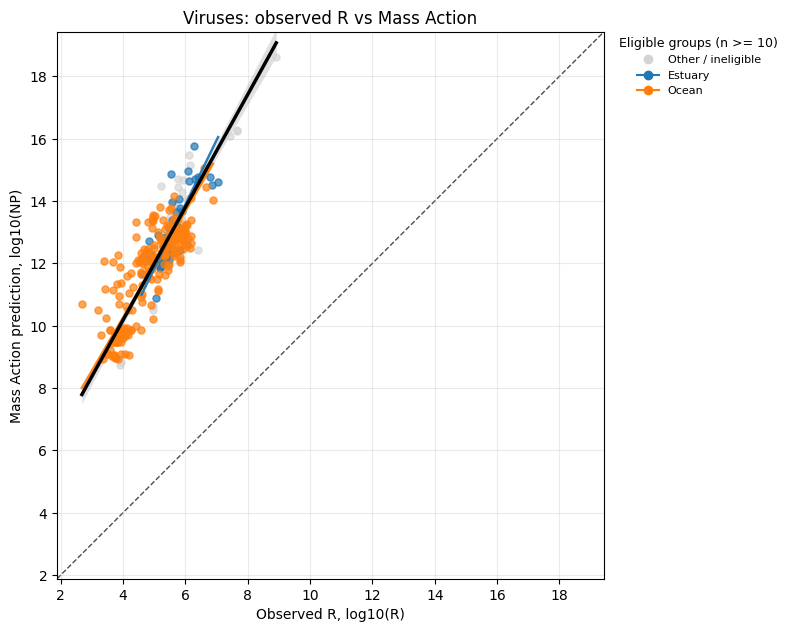

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10R_vs_log10PT.pdf


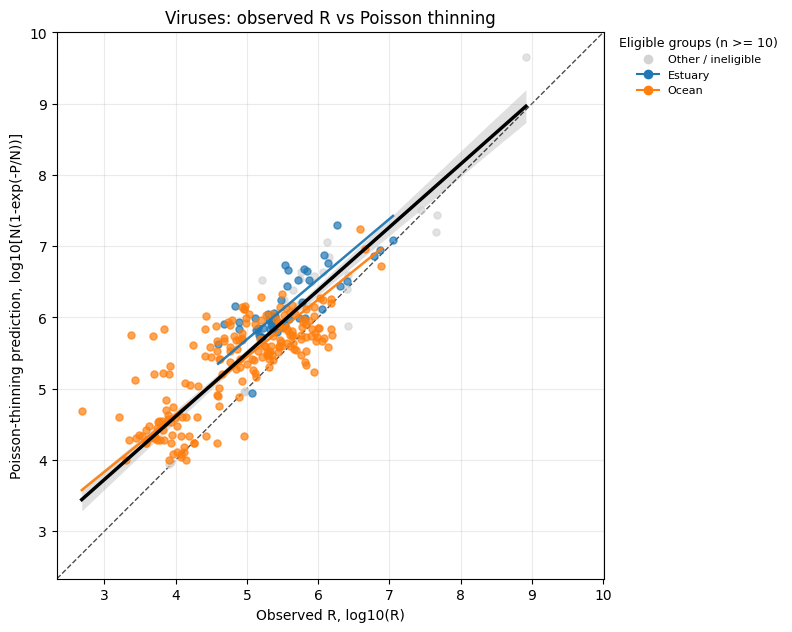

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10MA_vs_log10reqq.pdf


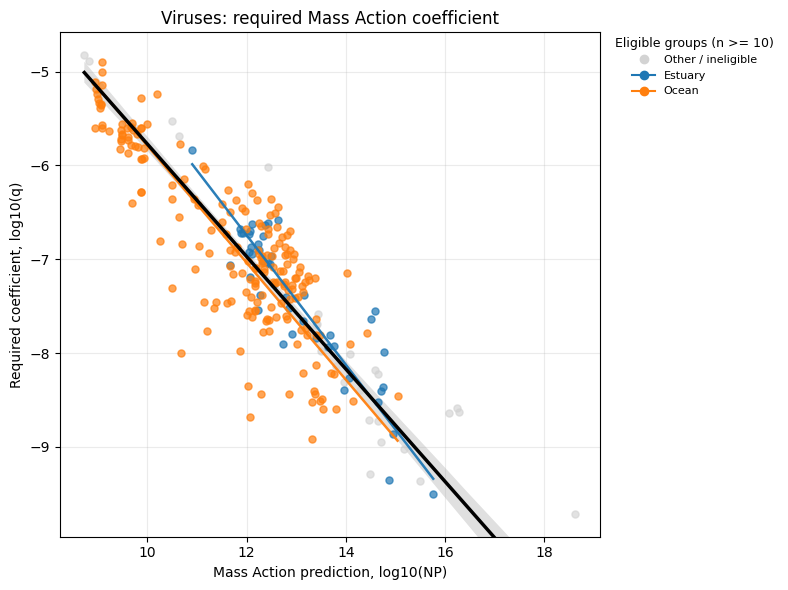

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10PT_vs_log10reqz.pdf


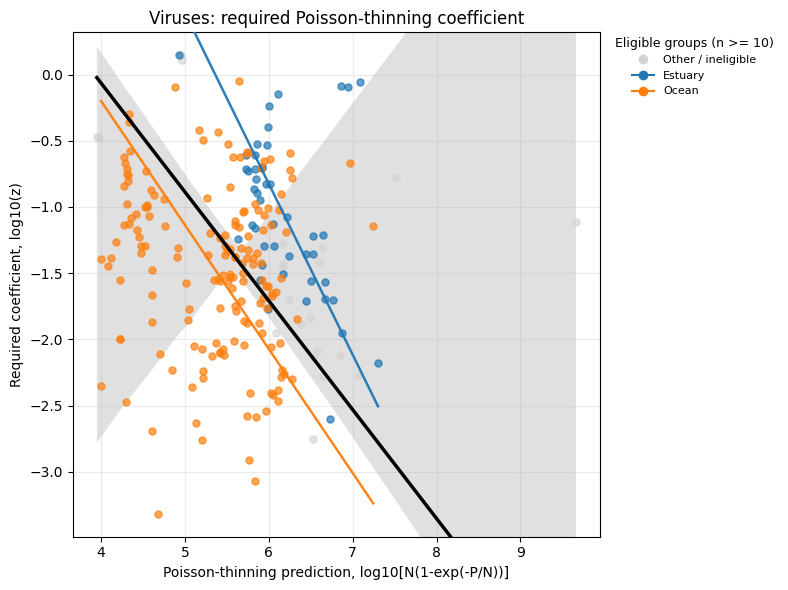

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_log10PT_vs_log10MA.pdf


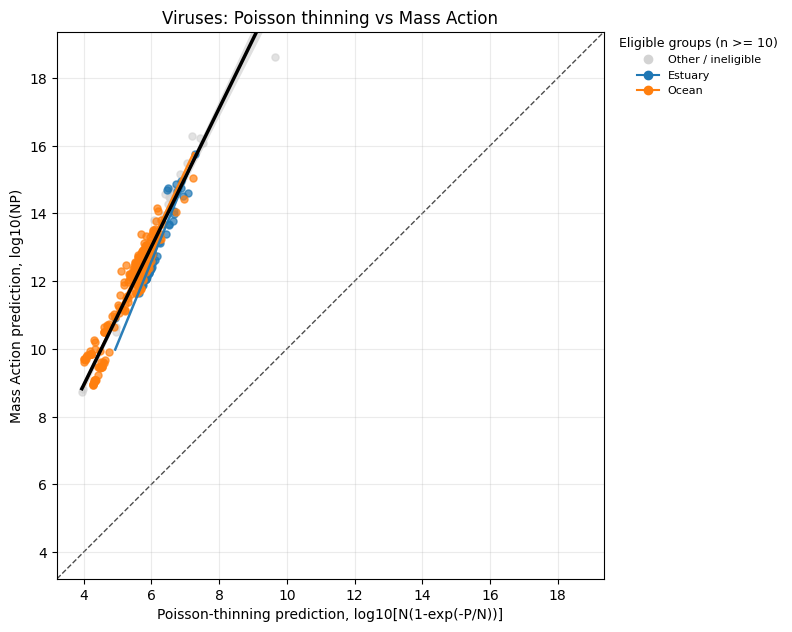

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_forest_MA_PT_merged.pdf


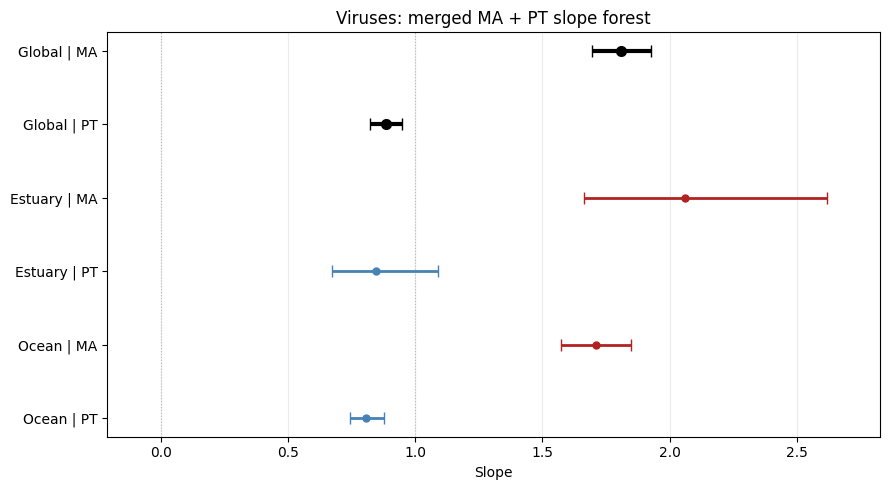

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_forest_reqq_reqz_merged.pdf


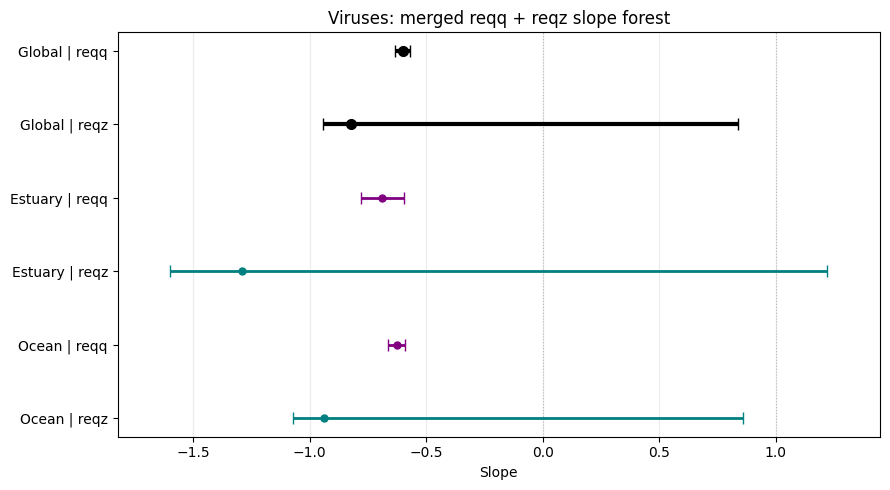

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_forest_crossover.pdf


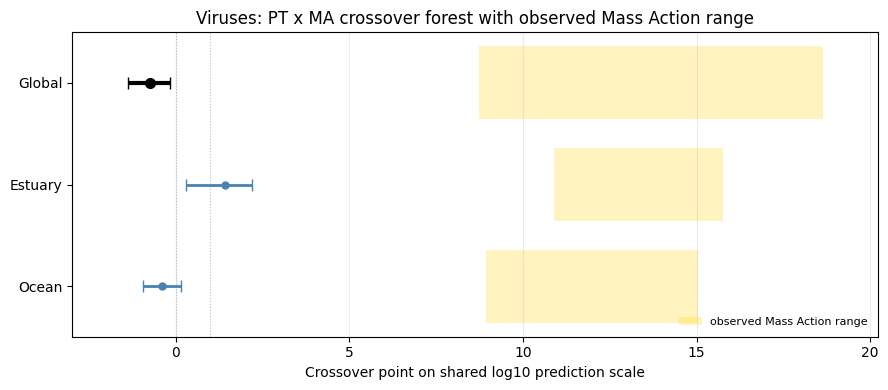

Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/tables/viruses_displayed_line_stats.csv
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/qc/viruses_plot_manifest.csv


In [13]:
# Cell 13: Shared plot generation and output manifest
# Generates the shared analysis figures and writes the output manifest.
# Produces PDF plots, plot metadata, fit summaries, and the final manifest table.

print_header("PHASE 5: Generate plots")

manifest_rows = []
displayed_stats_parts = []
for model_name, specification in MODEL_PLOT_SPECS.items():
    global_row = global_fits.loc[global_fits["model"].eq(model_name)].copy()
    group_rows = group_fits.loc[group_fits["model"].eq(model_name)].copy() if len(group_fits) else pd.DataFrame()
    stats = plot_global_plus_group_lines(analysis, global_row, group_rows, model_name, specification)
    displayed_stats_parts.append(stats)
    manifest_rows.append({
        "figure": model_name,
        "figure_type": "scatter_with_SMA_lines",
        "n_points": int(analysis[[specification["x"], specification["y"]]].dropna().shape[0]),
        "n_group_fits": int(len(group_rows)),
        "path": str(specification["path"]),
    })

manifest_rows.append(plot_merged_forest(
    ["MA", "PT"],
    {"MA": "firebrick", "PT": "steelblue"},
    f"{SYSTEM_NAME}: merged MA + PT slope forest",
    FOREST_MA_PT_MERGED_PATH,
))
manifest_rows.append(plot_merged_forest(
    ["reqq", "reqz"],
    {"reqq": "purple", "reqz": "teal"},
    f"{SYSTEM_NAME}: merged reqq + reqz slope forest",
    FOREST_REQQ_REQZ_MERGED_PATH,
))
manifest_rows.append(plot_crossover_forest(FOREST_CROSSOVER_PATH))

all_displayed_stats = pd.concat(displayed_stats_parts, ignore_index=True) if displayed_stats_parts else pd.DataFrame()
plot_manifest = pd.DataFrame(manifest_rows)
plot_manifest["exists"] = plot_manifest["path"].map(lambda path: Path(path).exists())

save_csv(all_displayed_stats, DISPLAYED_STATS_PATH, index=False)
save_csv(plot_manifest, PLOT_MANIFEST_PATH, index=False)



In [14]:
# Cell 14: Bayesian SMA configuration and dependencies
# Defines the symmetric Bayesian verification layer without changing primary SMA fits.

# This symmetric hierarchical Bayesian verification replaces the earlier
# collaborator-derived directional regression and subsequent theory-prior
# sensitivity experiments. The production Bayesian model now matches the
# Type-II/SMA inferential question used in the primary analysis.

bayesian_plot_manifest_rows = []
bayesian_line_stats = pd.DataFrame()
bayesian_model_diagnostics = pd.DataFrame()
bayesian_sma_comparison = pd.DataFrame()
bayesian_idata_by_model = {}


def load_bayesian_dependencies():
    global pm, az, pt
    try:
        import pymc as pm_import
        import arviz as az_import
        import pytensor.tensor as pt
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", "pymc", "arviz"]
        )
        import pymc as pm_import
        import arviz as az_import
        import pytensor.tensor as pt
    pm = pm_import
    az = az_import
    print(f"PyMC version: {pm.__version__}")
    print(f"ArviZ version: {az.__version__}")
    return pm, az


def load_arviz_dependency():
    global az
    if "az" in globals():
        return az
    try:
        import arviz as az_import
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arviz"])
        import arviz as az_import
    az = az_import
    print(f"ArviZ version: {az.__version__}")
    return az


def bayesian_context_fields():
    return {
        "system": SYSTEM_NAME,
        "year": ANALYSIS_YEAR if ANALYSIS_YEAR is not None else np.nan,
        "P_definition": PRIMARY_P_DEFINITION if PRIMARY_P_DEFINITION is not None else np.nan,
    }


def bayesian_prior_widths(multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    multiplier = float(multiplier)
    if not np.isfinite(multiplier) or multiplier <= 0:
        raise ValueError("Bayesian prior-width multiplier must be finite and positive")
    return {
        "prior_location_sd": BAYES_PRIOR_LOCATION_SD * multiplier,
        "prior_log_scale_sd": BAYES_PRIOR_LOG_SCALE_SD * multiplier,
        "prior_fisher_rho_sd": BAYES_PRIOR_FISHER_RHO_SD * multiplier,
        "prior_group_location_sd": BAYES_PRIOR_GROUP_LOCATION_SD * multiplier,
        "prior_group_log_scale_sd": BAYES_PRIOR_GROUP_LOG_SCALE_SD * multiplier,
        "prior_group_fisher_rho_sd": BAYES_PRIOR_GROUP_FISHER_RHO_SD * multiplier,
        "prior_width_multiplier": multiplier,
    }


def bayesian_figure_path(specification):
    source = Path(specification["path"])
    return source.with_name(f"{source.stem}_bayesian_sma{source.suffix}")


def bayesian_draws_dir():
    root = WORKING_DIR if "WORKING_DIR" in globals() else DATA_DIR / "working"
    return Path(root) / "bayesian_draws"


def save_bayesian_draws_if_requested(idata, fit_type, model_name):
    if not SAVE_BAYESIAN_DRAWS:
        return np.nan
    out_dir = ensure_dir(bayesian_draws_dir())
    out_path = out_dir / f"{SYSTEM_PREFIX}_{model_name}_{fit_type}{OUTPUT_SUFFIX}.nc"
    idata.to_netcdf(out_path)
    return str(out_path)



In [15]:
# Cell 15: Bayesian SMA helper functions
# Prepares identical relationship membership, symmetric MVN models, diagnostics, and summaries.

def prepare_bayesian_fit_data(df, xcol, ycol, group_col=None):
    required = [xcol, ycol] + ([group_col] if group_col is not None else [])
    check_required_columns(df, required, df_name="Bayesian SMA input")
    identity_columns = [col for col in ["analysis_obs_id", "obs_id"] if col in df.columns]
    columns = list(dict.fromkeys(identity_columns + required))
    sub = df[columns].copy()
    sub[xcol] = pd.to_numeric(sub[xcol], errors="coerce")
    sub[ycol] = pd.to_numeric(sub[ycol], errors="coerce")
    finite = np.isfinite(sub[xcol].to_numpy(dtype=float)) & np.isfinite(sub[ycol].to_numpy(dtype=float))
    sub = sub.loc[finite].copy().reset_index(drop=True)
    if group_col is not None:
        sub[group_col] = sub[group_col].astype(str)
    return sub


def standardize_bayesian_xy(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_center = float(np.mean(x))
    y_center = float(np.mean(y))
    x_scale = float(np.std(x, ddof=1))
    y_scale = float(np.std(y, ddof=1))
    constants = np.array([x_center, x_scale, y_center, y_scale], dtype=float)
    if not np.isfinite(constants).all() or x_scale <= 0 or y_scale <= 0:
        raise ValueError("Bayesian SMA standardization requires finite centers and positive sample SDs")
    return {
        "x": (x - x_center) / x_scale,
        "y": (y - y_center) / y_scale,
        "x_center": x_center,
        "x_scale": x_scale,
        "y_center": y_center,
        "y_scale": y_scale,
    }


def sma_slope_from_components(rho, sigma_x, sigma_y):
    return np.sign(rho) * np.asarray(sigma_y) / np.asarray(sigma_x)


def backtransform_sma_line(slope_std, intercept_std, standardization):
    slope = np.asarray(slope_std) * standardization["y_scale"] / standardization["x_scale"]
    intercept = (
        standardization["y_center"]
        + standardization["y_scale"] * np.asarray(intercept_std)
        - slope * standardization["x_center"]
    )
    return slope, intercept


def covariance_from_components(sigma_x, sigma_y, rho):
    return np.array(
        [[sigma_x ** 2, rho * sigma_x * sigma_y],
         [rho * sigma_x * sigma_y, sigma_y ** 2]],
        dtype=float,
    )


def bayesian_sma_helper_tests():
    """Runtime helper checks; defined here but not executed automatically."""
    assert np.isclose(sma_slope_from_components(0.5, 2.0, 6.0), 3.0)
    assert np.isclose(sma_slope_from_components(-0.5, 2.0, 6.0), -3.0)
    slope_xy = sma_slope_from_components(0.5, 2.0, 6.0)
    slope_yx = sma_slope_from_components(0.5, 6.0, 2.0)
    assert np.isclose(slope_xy * slope_yx, 1.0)
    constants = {"x_center": 3.0, "x_scale": 2.0, "y_center": -1.0, "y_scale": 4.0}
    expected_slope, expected_intercept = 1.5, -0.25
    slope_std = expected_slope * constants["x_scale"] / constants["y_scale"]
    intercept_std = (
        expected_intercept - constants["y_center"] + expected_slope * constants["x_center"]
    ) / constants["y_scale"]
    recovered = backtransform_sma_line(slope_std, intercept_std, constants)
    assert np.allclose(recovered, [expected_slope, expected_intercept])
    for sigma_x, sigma_y in [(0.2, 0.5), (1.0, 1.0), (2.0, 3.0)]:
        for fisher_rho in [-3.0, -0.7, 0.0, 0.7, 3.0]:
            covariance = covariance_from_components(sigma_x, sigma_y, np.tanh(fisher_rho))
            assert np.all(np.linalg.eigvalsh(covariance) > -1e-12)
    return True


def current_eligible_groups(keep_col, group_col=GROUP_COL):
    check_required_columns(group_eligibility, [group_col, keep_col], df_name="group_eligibility")
    groups = group_eligibility.loc[group_eligibility[keep_col], group_col].dropna().astype(str).tolist()
    if len(groups) != len(set(groups)):
        raise RuntimeError(f"Duplicate eligible group labels for {keep_col}")
    return groups


def assert_pooled_membership(sub, model_name):
    classical = global_fits.loc[global_fits["model"].eq(model_name), "n"]
    if len(classical) != 1 or int(classical.iloc[0]) != len(sub):
        raise RuntimeError(f"Pooled Bayesian membership differs from global SMA for {model_name}")


def prepare_bayesian_hierarchical_data(df, spec, model_name, group_col=GROUP_COL):
    groups = current_eligible_groups(spec["keep_col"], group_col=group_col)
    if len(groups) < 2:
        raise ValueError(f"Hierarchical Bayesian SMA requires at least two eligible groups for {model_name}")
    finite = prepare_bayesian_fit_data(df, spec["xcol"], spec["ycol"], group_col=group_col)
    sub = finite.loc[finite[group_col].isin(groups)].copy().reset_index(drop=True)
    counts = sub.groupby(group_col).size().reindex(groups)
    if counts.isna().any() or set(sub[group_col]) != set(groups):
        raise RuntimeError(f"Bayesian groups differ from group_eligibility for {model_name}")
    classical = group_fits.loc[group_fits["model"].eq(model_name), ["group_label", "n"]].copy()
    classical_counts = classical.set_index("group_label")["n"].to_dict()
    for group_name, count in counts.items():
        if int(classical_counts.get(group_name, -1)) != int(count):
            raise RuntimeError(f"Bayesian and classical group membership differ for {model_name} / {group_name}")
    group_index = pd.Categorical(sub[group_col], categories=groups, ordered=True).codes.astype(int)
    standardized = standardize_bayesian_xy(sub[spec["xcol"]], sub[spec["ycol"]])
    return {
        "data": sub,
        "group_names": groups,
        "group_index": group_index,
        "group_counts": counts.astype(int).to_dict(),
        **standardized,
    }


def _factorized_bivariate_gaussian_likelihood(
    name_prefix, observed_x, observed_y, mu_x, mu_y, sigma_x, sigma_y, rho, dims=None,
):
    """Same joint MVN density evaluated as p(x) * p(y | x)."""
    prefix = f"{name_prefix}_" if name_prefix else ""
    x_observation = pm.Normal(
        f"{prefix}x_obs", mu=mu_x, sigma=sigma_x, observed=observed_x, dims=dims
    )
    conditional_y_mean = mu_y + rho * (sigma_y / sigma_x) * (x_observation - mu_x)
    conditional_y_sigma = sigma_y * pm.math.sqrt(1.0 - rho ** 2)
    pm.Normal(
        f"{prefix}y_obs", mu=conditional_y_mean, sigma=conditional_y_sigma,
        observed=observed_y, dims=dims,
    )


def _deterministic_original_line(prefix, mu_x, mu_y, sigma_x, sigma_y, rho, standardization, dims=None):
    slope_std = pt.sign(rho) * sigma_y / sigma_x
    intercept_std = mu_y - slope_std * mu_x
    slope = pm.Deterministic(
        f"{prefix}sma_slope", slope_std * standardization["y_scale"] / standardization["x_scale"], dims=dims
    )
    intercept = pm.Deterministic(
        f"{prefix}sma_intercept",
        standardization["y_center"] + standardization["y_scale"] * intercept_std
        - slope * standardization["x_center"],
        dims=dims,
    )
    pm.Deterministic(f"{prefix}rho", rho, dims=dims)
    pm.Deterministic(f"{prefix}sigma_x", sigma_x * standardization["x_scale"], dims=dims)
    pm.Deterministic(f"{prefix}sigma_y", sigma_y * standardization["y_scale"], dims=dims)
    return slope, intercept


def build_bayesian_pooled_sma_model(prepared, prior_multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    widths = bayesian_prior_widths(prior_multiplier)
    with pm.Model(coords={"observation": np.arange(len(prepared["x"]))}) as model:
        mu_x = pm.Normal("mu_x", 0.0, widths["prior_location_sd"])
        mu_y = pm.Normal("mu_y", 0.0, widths["prior_location_sd"])
        log_sigma_x = pm.Normal("log_sigma_x", 0.0, widths["prior_log_scale_sd"])
        log_sigma_y = pm.Normal("log_sigma_y", 0.0, widths["prior_log_scale_sd"])
        fisher_rho = pm.Normal("fisher_rho", 0.0, widths["prior_fisher_rho_sd"])
        sigma_x = pm.math.exp(log_sigma_x)
        sigma_y = pm.math.exp(log_sigma_y)
        rho = pm.math.tanh(fisher_rho)
        _deterministic_original_line("", mu_x, mu_y, sigma_x, sigma_y, rho, prepared)
        _factorized_bivariate_gaussian_likelihood(
            "", prepared["x"], prepared["y"], mu_x, mu_y,
            sigma_x, sigma_y, rho, dims="observation",
        )
    return model, widths


def build_bayesian_hierarchical_sma_model(prepared, prior_multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    widths = bayesian_prior_widths(prior_multiplier)
    coords = {"group": prepared["group_names"]}
    with pm.Model(coords=coords) as model:
        mu_x_population = pm.Normal("mu_x_population", 0.0, widths["prior_location_sd"])
        mu_y_population = pm.Normal("mu_y_population", 0.0, widths["prior_location_sd"])
        tau_mu_x = pm.HalfNormal("tau_mu_x", widths["prior_group_location_sd"])
        tau_mu_y = pm.HalfNormal("tau_mu_y", widths["prior_group_location_sd"])
        z_mu_x = pm.Normal("z_mu_x", 0.0, 1.0, dims="group")
        z_mu_y = pm.Normal("z_mu_y", 0.0, 1.0, dims="group")
        mu_x_group = pm.Deterministic("mu_x_group", mu_x_population + tau_mu_x * z_mu_x, dims="group")
        mu_y_group = pm.Deterministic("mu_y_group", mu_y_population + tau_mu_y * z_mu_y, dims="group")

        log_sigma_x_population = pm.Normal("log_sigma_x_population", 0.0, widths["prior_log_scale_sd"])
        log_sigma_y_population = pm.Normal("log_sigma_y_population", 0.0, widths["prior_log_scale_sd"])
        tau_log_sigma_x = pm.HalfNormal("tau_log_sigma_x", widths["prior_group_log_scale_sd"])
        tau_log_sigma_y = pm.HalfNormal("tau_log_sigma_y", widths["prior_group_log_scale_sd"])
        z_log_sigma_x = pm.Normal("z_log_sigma_x", 0.0, 1.0, dims="group")
        z_log_sigma_y = pm.Normal("z_log_sigma_y", 0.0, 1.0, dims="group")
        sigma_x_population = pm.math.exp(log_sigma_x_population)
        sigma_y_population = pm.math.exp(log_sigma_y_population)
        sigma_x_group_std = pm.math.exp(log_sigma_x_population + tau_log_sigma_x * z_log_sigma_x)
        sigma_y_group_std = pm.math.exp(log_sigma_y_population + tau_log_sigma_y * z_log_sigma_y)

        fisher_rho_population = pm.Normal("fisher_rho_population", 0.0, widths["prior_fisher_rho_sd"])
        tau_fisher_rho = pm.HalfNormal("tau_fisher_rho", widths["prior_group_fisher_rho_sd"])
        z_fisher_rho = pm.Normal("z_fisher_rho", 0.0, 1.0, dims="group")
        rho_population_std = pm.math.tanh(fisher_rho_population)
        rho_group_std = pm.math.tanh(fisher_rho_population + tau_fisher_rho * z_fisher_rho)

        _deterministic_original_line(
            "population_", mu_x_population, mu_y_population, sigma_x_population,
            sigma_y_population, rho_population_std, prepared,
        )
        _deterministic_original_line(
            "group_", mu_x_group, mu_y_group, sigma_x_group_std,
            sigma_y_group_std, rho_group_std, prepared, dims="group",
        )
        for group_number, group_name in enumerate(prepared["group_names"]):
            group_mask = prepared["group_index"] == group_number
            _factorized_bivariate_gaussian_likelihood(
                f"group_{group_number}",
                prepared["x"][group_mask], prepared["y"][group_mask],
                mu_x_group[group_number], mu_y_group[group_number],
                sigma_x_group_std[group_number], sigma_y_group_std[group_number],
                rho_group_std[group_number],
            )
    return model, widths


def sample_bayesian_sma_model(model, fit_type):
    with model:
        prior = pm.sample_prior_predictive(
            samples=BAYES_PRIOR_PREDICTIVE_DRAWS,
            random_seed=RANDOM_SEED,
            return_inferencedata=True,
        )
        sample_kwargs = {
            "draws": BAYES_DRAWS,
            "tune": BAYES_TUNE,
            "chains": BAYES_CHAINS,
            "cores": min(BAYES_CHAINS, os.cpu_count() or 1),
            "random_seed": RANDOM_SEED,
            "return_inferencedata": True,
        }
        if fit_type == "hierarchical":
            sample_kwargs.update(
                target_accept=BAYES_TARGET_ACCEPT_HIERARCHICAL,
                nuts={"max_treedepth": BAYES_MAX_TREEDEPTH_HIERARCHICAL},
            )
        idata = pm.sample(**sample_kwargs)
        posterior_predictive = pm.sample_posterior_predictive(
            idata, random_seed=RANDOM_SEED, return_inferencedata=True
        )
    idata.extend(prior)
    idata.extend(posterior_predictive)
    return idata


def posterior_values(idata, var_name, selector=None, group="posterior"):
    values = getattr(idata, group)[var_name]
    if selector:
        values = values.sel(selector)
    return np.asarray(values).reshape(-1)


def diagnostic_scalar(idata, var_name, selector, kind):
    if kind == "rhat":
        values = az.rhat(idata, var_names=[var_name])[var_name]
    else:
        values = az.ess(idata, var_names=[var_name], method=kind)[var_name]
    if selector:
        values = values.sel(selector)
    array = np.asarray(values, dtype=float)
    reducer = np.nanmax if kind == "rhat" else np.nanmin
    return float(reducer(array))


def distribution_summary(values, prefix, include_05_95=False):
    values = np.asarray(values, dtype=float).reshape(-1)
    result = {
        f"{prefix}_mean": float(np.mean(values)),
        f"{prefix}_median": float(np.median(values)),
        f"{prefix}_q025": float(np.percentile(values, 2.5)),
        f"{prefix}_q975": float(np.percentile(values, 97.5)),
    }
    if include_05_95:
        result.update({
            f"{prefix}_q05": float(np.percentile(values, 5.0)),
            f"{prefix}_q95": float(np.percentile(values, 95.0)),
        })
    return result


def bayesian_line_summary(idata, model_name, fit_level, group_label, n, n_groups, xcol, ycol, variables, selector=None):
    slope = posterior_values(idata, variables["slope"], selector)
    intercept = posterior_values(idata, variables["intercept"], selector)
    rho = posterior_values(idata, variables["rho"], selector)
    sigma_x = posterior_values(idata, variables["sigma_x"], selector)
    sigma_y = posterior_values(idata, variables["sigma_y"], selector)
    reference = float(SLOPE_REFERENCE_VALUES[model_name])
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_level": fit_level,
        "group_label": group_label, "is_global": fit_level == "pooled_global",
        "xcol": xcol, "ycol": ycol, "n": int(n), "n_groups": int(n_groups),
        "reference_slope": reference,
        "p_slope_below_reference": float(np.mean(slope < reference)),
        "p_slope_above_reference": float(np.mean(slope > reference)),
        "fit_status": "completed",
    }
    row.update(distribution_summary(slope, "slope", include_05_95=True))
    row.update(distribution_summary(intercept, "intercept", include_05_95=True))
    row.update(distribution_summary(rho, "rho"))
    row.update(distribution_summary(sigma_x, "sigma_x"))
    row.update(distribution_summary(sigma_y, "sigma_y"))
    for prefix, variable in variables.items():
        if prefix not in {"slope", "intercept", "rho", "sigma_x", "sigma_y"}:
            continue
        row[f"{prefix}_rhat"] = diagnostic_scalar(idata, variable, selector, "rhat")
        row[f"{prefix}_ess_bulk"] = diagnostic_scalar(idata, variable, selector, "bulk")
        row[f"{prefix}_ess_tail"] = diagnostic_scalar(idata, variable, selector, "tail")
    rhats = [row[f"{name}_rhat"] for name in ["slope", "intercept", "rho", "sigma_x", "sigma_y"]]
    row["max_line_rhat"] = float(np.nanmax(rhats))
    row["rhat_converged"] = bool(row["max_line_rhat"] <= BAYES_RHAT_THRESHOLD)
    return row


def failed_line_rows(
    model_name, spec, fit_type, group_names=None, group_counts=None,
    total_n=np.nan, error_message="",
):
    keys = ["slope", "intercept", "rho", "sigma_x", "sigma_y"]
    levels = [("pooled_global", "Global", total_n)] if fit_type == "pooled_global" else [
        ("hierarchical_population", "Hierarchical population", total_n)
    ] + [("hierarchical_group", group, (group_counts or {}).get(group, np.nan)) for group in (group_names or [])]
    rows = []
    for level, label, n in levels:
        row = {
            **bayesian_context_fields(), "model": model_name, "fit_level": level,
            "group_label": label, "is_global": level == "pooled_global",
            "xcol": spec["xcol"], "ycol": spec["ycol"], "n": n,
            "n_groups": len(group_names or []), "reference_slope": SLOPE_REFERENCE_VALUES[model_name],
            "fit_status": "failed", "error_message": str(error_message), "rhat_converged": False,
        }
        for key in keys:
            for suffix in ["mean", "median", "q025", "q975", "rhat", "ess_bulk", "ess_tail"]:
                row[f"{key}_{suffix}"] = np.nan
        for key in ["slope", "intercept"]:
            row[f"{key}_q05"] = np.nan
            row[f"{key}_q95"] = np.nan
        row.update(p_slope_below_reference=np.nan, p_slope_above_reference=np.nan, max_line_rhat=np.nan)
        rows.append(row)
    return rows


def _joint_statistics(values):
    return np.array([
        np.mean(values[..., 0], axis=-1), np.mean(values[..., 1], axis=-1),
        np.std(values[..., 0], axis=-1, ddof=1), np.std(values[..., 1], axis=-1, ddof=1),
        np.array([np.corrcoef(draw[:, 0], draw[:, 1])[0, 1] for draw in values.reshape(-1, values.shape[-2], 2)]).reshape(values.shape[:-2]),
    ])


def ppc_coverage(observed, predicted):
    observed_stats = _joint_statistics(np.asarray(observed)[None, ...]).reshape(5)
    predicted_stats = _joint_statistics(np.asarray(predicted).reshape(-1, predicted.shape[-2], 2))
    labels = ["mean_x", "mean_y", "sd_x", "sd_y", "r"]
    return {
        label: bool(np.percentile(predicted_stats[index], 2.5) <= observed_stats[index]
                    <= np.percentile(predicted_stats[index], 97.5))
        for index, label in enumerate(labels)
    }


def posterior_predictive_xy(idata, x_name, y_name):
    predicted_x = np.asarray(idata.posterior_predictive[x_name])
    predicted_y = np.asarray(idata.posterior_predictive[y_name])
    return np.stack([predicted_x, predicted_y], axis=-1)


def summarize_ppc(idata, prepared, fit_type):
    if fit_type == "pooled_global":
        observed = np.column_stack([prepared["x"], prepared["y"]])
        predicted = posterior_predictive_xy(idata, "x_obs", "y_obs")
        return {f"ppc_{name}_covered": value for name, value in ppc_coverage(observed, predicted).items()}
    covered = []
    for number in range(len(prepared["group_names"])):
        mask = prepared["group_index"] == number
        observed = np.column_stack([prepared["x"][mask], prepared["y"][mask]])
        predicted = posterior_predictive_xy(
            idata, f"group_{number}_x_obs", f"group_{number}_y_obs"
        )
        covered.append(ppc_coverage(observed, predicted))
    return {
        f"ppc_fraction_groups_{name}_covered": float(np.mean([row[name] for row in covered]))
        for name in ["mean_x", "mean_y", "sd_x", "sd_y", "r"]
    }


def prior_slope_summary(idata, fit_type):
    variable = "sma_slope" if fit_type == "pooled_global" else "population_sma_slope"
    values = posterior_values(idata, variable, group="prior")
    return {
        "prior_slope_q025": float(np.percentile(values, 2.5)),
        "prior_slope_q50": float(np.percentile(values, 50.0)),
        "prior_slope_q975": float(np.percentile(values, 97.5)),
    }


def model_diagnostics(idata, model_name, spec, fit_type, prepared, widths):
    rhat = np.asarray(az.rhat(idata).to_array(), dtype=float)
    ess_bulk = np.asarray(az.ess(idata, method="bulk").to_array(), dtype=float)
    ess_tail = np.asarray(az.ess(idata, method="tail").to_array(), dtype=float)
    divergences = int(np.asarray(idata.sample_stats["diverging"]).sum())
    depths = np.asarray(idata.sample_stats["tree_depth"])
    max_depth = BAYES_MAX_TREEDEPTH_HIERARCHICAL if fit_type == "hierarchical" else np.nan
    treedepth_hits = int(np.sum(depths >= max_depth)) if np.isfinite(max_depth) else 0
    max_rhat = float(np.nanmax(rhat))
    converged_rhat = bool(max_rhat <= BAYES_RHAT_THRESHOLD)
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_type": fit_type,
        "xcol": spec["xcol"], "ycol": spec["ycol"], "n": len(prepared["x"]),
        "n_groups": len(prepared.get("group_names", [])),
        "x_center": prepared["x_center"], "x_scale": prepared["x_scale"],
        "y_center": prepared["y_center"], "y_scale": prepared["y_scale"],
        **widths, "chains": BAYES_CHAINS, "draws": BAYES_DRAWS, "tune": BAYES_TUNE,
        "target_accept": BAYES_TARGET_ACCEPT_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "max_treedepth": max_depth, "random_seed": RANDOM_SEED,
        "max_model_rhat": max_rhat, "min_ess_bulk": float(np.nanmin(ess_bulk)),
        "min_ess_tail": float(np.nanmin(ess_tail)), "divergences": divergences,
        "treedepth_hits": treedepth_hits, "rhat_threshold": BAYES_RHAT_THRESHOLD,
        "model_rhat_converged": converged_rhat, "zero_divergences": divergences == 0,
        "model_converged": converged_rhat and divergences == 0,
        "fit_status": "completed", "error_message": "",
    }
    row.update(prior_slope_summary(idata, fit_type))
    row.update(summarize_ppc(idata, prepared, fit_type))
    return row


def failed_model_diagnostic(
    model_name, spec, fit_type, prepared=None, error_message="",
    n_override=None, n_groups_override=None,
):
    widths = bayesian_prior_widths()
    prepared = prepared or {}
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_type": fit_type,
        "xcol": spec["xcol"], "ycol": spec["ycol"],
        "n": len(prepared.get("x", [])) if n_override is None else n_override,
        "n_groups": len(prepared.get("group_names", [])) if n_groups_override is None else n_groups_override,
        **widths,
        "x_center": prepared.get("x_center", np.nan), "x_scale": prepared.get("x_scale", np.nan),
        "y_center": prepared.get("y_center", np.nan), "y_scale": prepared.get("y_scale", np.nan),
        "chains": BAYES_CHAINS, "draws": BAYES_DRAWS, "tune": BAYES_TUNE,
        "target_accept": BAYES_TARGET_ACCEPT_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "max_treedepth": BAYES_MAX_TREEDEPTH_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "random_seed": RANDOM_SEED, "rhat_threshold": BAYES_RHAT_THRESHOLD,
        "max_model_rhat": np.nan, "min_ess_bulk": np.nan, "min_ess_tail": np.nan,
        "divergences": np.nan, "treedepth_hits": np.nan, "model_rhat_converged": False,
        "zero_divergences": False, "model_converged": False, "fit_status": "failed",
        "error_message": str(error_message), "prior_slope_q025": np.nan,
        "prior_slope_q50": np.nan, "prior_slope_q975": np.nan,
    }
    for name in ["mean_x", "mean_y", "sd_x", "sd_y", "r"]:
        row[f"ppc_{name}_covered"] = np.nan
        row[f"ppc_fraction_groups_{name}_covered"] = np.nan
    return row


POOLED_LINE_VARIABLES = {
    "slope": "sma_slope", "intercept": "sma_intercept", "rho": "rho",
    "sigma_x": "sigma_x", "sigma_y": "sigma_y",
}
POPULATION_LINE_VARIABLES = {
    "slope": "population_sma_slope", "intercept": "population_sma_intercept",
    "rho": "population_rho", "sigma_x": "population_sigma_x", "sigma_y": "population_sigma_y",
}
GROUP_LINE_VARIABLES = {
    "slope": "group_sma_slope", "intercept": "group_sma_intercept", "rho": "group_rho",
    "sigma_x": "group_sigma_x", "sigma_y": "group_sigma_y",
}

BAYESIAN_LINE_STATS_COLUMNS = [
    "system", "year", "P_definition", "model", "fit_level", "group_label",
    "is_global", "xcol", "ycol", "n", "n_groups",
    "slope_mean", "slope_median", "slope_q025", "slope_q05", "slope_q95", "slope_q975",
    "intercept_mean", "intercept_median", "intercept_q025", "intercept_q05",
    "intercept_q95", "intercept_q975",
    "rho_mean", "rho_median", "rho_q025", "rho_q975",
    "sigma_x_mean", "sigma_x_median", "sigma_x_q025", "sigma_x_q975",
    "sigma_y_mean", "sigma_y_median", "sigma_y_q025", "sigma_y_q975",
    "reference_slope", "p_slope_below_reference", "p_slope_above_reference",
    "slope_rhat", "slope_ess_bulk", "slope_ess_tail",
    "intercept_rhat", "intercept_ess_bulk", "intercept_ess_tail",
    "rho_rhat", "rho_ess_bulk", "rho_ess_tail",
    "sigma_x_rhat", "sigma_x_ess_bulk", "sigma_x_ess_tail",
    "sigma_y_rhat", "sigma_y_ess_bulk", "sigma_y_ess_tail",
    "max_line_rhat", "rhat_converged", "fit_status", "error_message",
]

BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS = [
    "system", "year", "P_definition", "model", "fit_type", "xcol", "ycol", "n", "n_groups",
    "prior_location_sd", "prior_log_scale_sd", "prior_fisher_rho_sd",
    "prior_group_location_sd", "prior_group_log_scale_sd", "prior_group_fisher_rho_sd",
    "prior_width_multiplier", "x_center", "x_scale", "y_center", "y_scale",
    "chains", "draws", "tune", "target_accept", "max_treedepth", "random_seed",
    "max_model_rhat", "min_ess_bulk", "min_ess_tail", "divergences", "treedepth_hits",
    "rhat_threshold", "model_rhat_converged", "zero_divergences", "model_converged",
    "fit_status", "error_message", "prior_slope_q025", "prior_slope_q50", "prior_slope_q975",
    "ppc_mean_x_covered", "ppc_mean_y_covered", "ppc_sd_x_covered", "ppc_sd_y_covered",
    "ppc_r_covered", "ppc_fraction_groups_mean_x_covered",
    "ppc_fraction_groups_mean_y_covered", "ppc_fraction_groups_sd_x_covered",
    "ppc_fraction_groups_sd_y_covered", "ppc_fraction_groups_r_covered",
]


def build_classical_bayesian_sma_comparison(line_stats):
    rows = []
    pooled = line_stats.loc[line_stats["fit_level"].eq("pooled_global")]
    for _, bayes_row in pooled.iterrows():
        classical = global_fits.loc[global_fits["model"].eq(bayes_row["model"])]
        if len(classical) == 1:
            rows.append({
                "model": bayes_row["model"], "fit_level": "pooled_global", "group_label": "Global",
                "n": bayes_row["n"], "classical_sma_slope": classical.iloc[0]["slope"],
                "bayesian_sma_slope_median": bayes_row["slope_median"],
                "difference": bayes_row["slope_median"] - classical.iloc[0]["slope"],
            })
    groups = line_stats.loc[line_stats["fit_level"].eq("hierarchical_group")]
    for _, bayes_row in groups.iterrows():
        classical = group_fits.loc[
            group_fits["model"].eq(bayes_row["model"])
            & group_fits["group_label"].eq(bayes_row["group_label"])
        ]
        if len(classical) == 1:
            rows.append({
                "model": bayes_row["model"], "fit_level": "hierarchical_group",
                "group_label": bayes_row["group_label"], "n": bayes_row["n"],
                "classical_sma_slope": classical.iloc[0]["slope"],
                "bayesian_sma_slope_median": bayes_row["slope_median"],
                "difference": bayes_row["slope_median"] - classical.iloc[0]["slope"],
            })
    return pd.DataFrame(rows)


def bayesian_model_names_to_run():
    if BAYES_MODELS_TO_RUN is None:
        return list(MODEL_SPECS)
    if isinstance(BAYES_MODELS_TO_RUN, str) or not isinstance(BAYES_MODELS_TO_RUN, (tuple, list)):
        raise TypeError("BAYES_MODELS_TO_RUN must be None or a tuple/list of MODEL_SPECS names")
    selected = list(BAYES_MODELS_TO_RUN)
    if not selected:
        raise ValueError("BAYES_MODELS_TO_RUN cannot be empty; use None for all Bayesian models")
    if not all(isinstance(model_name, str) for model_name in selected):
        raise TypeError("Every BAYES_MODELS_TO_RUN entry must be a MODEL_SPECS name string")
    if len(selected) != len(set(selected)):
        raise ValueError("BAYES_MODELS_TO_RUN contains duplicate model names")
    unknown = sorted(set(selected) - set(MODEL_SPECS))
    if unknown:
        raise ValueError(f"Unknown BAYES_MODELS_TO_RUN names: {unknown}")
    return selected


BAYESIAN_CHECKPOINT_SCHEMA_VERSION = "bayesian-relationship-checkpoint-v1"


def checkpoint_jsonable(value):
    if isinstance(value, dict):
        return {
            str(key): checkpoint_jsonable(value[key])
            for key in sorted(value, key=lambda item: str(item))
        }
    if isinstance(value, (list, tuple)):
        return [checkpoint_jsonable(item) for item in value]
    if isinstance(value, np.ndarray):
        return [checkpoint_jsonable(item) for item in value.tolist()]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        numeric = float(value)
        return numeric if np.isfinite(numeric) else None
    if value is None:
        return None
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return str(value) if not isinstance(value, str) else value


def checkpoint_json_dumps(value):
    return json.dumps(
        checkpoint_jsonable(value),
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )


def checkpoint_json_sha256(value):
    return hashlib.sha256(checkpoint_json_dumps(value).encode("utf-8")).hexdigest()


def bayesian_checkpoint_relationship_dir(model_name):
    return Path(BAYESIAN_CHECKPOINT_DIR) / model_name


def bayesian_checkpoint_file_stem(model_name):
    return f"{SYSTEM_PREFIX}_{model_name}{OUTPUT_SUFFIX}"


def bayesian_checkpoint_filenames(model_name):
    stem = bayesian_checkpoint_file_stem(model_name)
    return {
        "pooled_idata": f"{stem}_pooled_global.nc",
        "hierarchical_idata": f"{stem}_hierarchical.nc",
        "line_stats": f"{stem}_line_stats.csv",
        "model_diagnostics": f"{stem}_model_diagnostics.csv",
        "manifest": f"{stem}_manifest.json",
        "marker": f"{stem}_COMPLETE.json",
    }


def bayesian_checkpoint_identity_columns(df, spec, include_group=False):
    columns = [col for col in ["analysis_obs_id", "obs_id"] if col in df.columns]
    columns.extend([spec["xcol"], spec["ycol"]])
    if include_group and GROUP_COL in df.columns:
        columns.append(GROUP_COL)
    return list(dict.fromkeys(columns))


def dataframe_checkpoint_sha256(df, columns):
    records = [
        [checkpoint_jsonable(value) for value in row]
        for row in df.loc[:, columns].itertuples(index=False, name=None)
    ]
    return checkpoint_json_sha256({"columns": columns, "records": records})


def bayesian_checkpoint_standardization(prepared):
    return {
        "x_center": prepared["x_center"],
        "x_scale": prepared["x_scale"],
        "y_center": prepared["y_center"],
        "y_scale": prepared["y_scale"],
    }


def bayesian_checkpoint_expected_metadata(model_name, spec, pooled_sub, pooled_prepared, hierarchical_prepared):
    pooled_columns = bayesian_checkpoint_identity_columns(pooled_sub, spec, include_group=False)
    hierarchical_columns = bayesian_checkpoint_identity_columns(
        hierarchical_prepared["data"], spec, include_group=True
    )
    return {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "system_name": SYSTEM_NAME,
        "system_prefix": SYSTEM_PREFIX,
        "analysis_year": ANALYSIS_YEAR,
        "P_definition": PRIMARY_P_DEFINITION,
        "output_suffix": OUTPUT_SUFFIX,
        "model": model_name,
        "xcol": spec["xcol"],
        "ycol": spec["ycol"],
        "keep_col": spec["keep_col"],
        "model_spec": dict(spec),
        "fit_membership_n": int(len(pooled_sub)),
        "hierarchical_fit_membership_n": int(len(hierarchical_prepared["data"])),
        "hierarchical_group_names": [str(group) for group in hierarchical_prepared["group_names"]],
        "hierarchical_group_counts": {
            str(group): int(count)
            for group, count in hierarchical_prepared["group_counts"].items()
        },
        "random_seed": int(RANDOM_SEED),
        "bayes_chains": int(BAYES_CHAINS),
        "bayes_draws": int(BAYES_DRAWS),
        "bayes_tune": int(BAYES_TUNE),
        "bayes_prior_predictive_draws": int(BAYES_PRIOR_PREDICTIVE_DRAWS),
        "bayes_target_accept_hierarchical": float(BAYES_TARGET_ACCEPT_HIERARCHICAL),
        "bayes_max_treedepth_hierarchical": int(BAYES_MAX_TREEDEPTH_HIERARCHICAL),
        "bayes_rhat_threshold": float(BAYES_RHAT_THRESHOLD),
        "bayes_prior_width_multiplier": float(BAYES_PRIOR_WIDTH_MULTIPLIER),
        "bayes_prior_location_sd": float(BAYES_PRIOR_LOCATION_SD),
        "bayes_prior_log_scale_sd": float(BAYES_PRIOR_LOG_SCALE_SD),
        "bayes_prior_fisher_rho_sd": float(BAYES_PRIOR_FISHER_RHO_SD),
        "bayes_prior_group_location_sd": float(BAYES_PRIOR_GROUP_LOCATION_SD),
        "bayes_prior_group_log_scale_sd": float(BAYES_PRIOR_GROUP_LOG_SCALE_SD),
        "bayes_prior_group_fisher_rho_sd": float(BAYES_PRIOR_GROUP_FISHER_RHO_SD),
        "min_group_n": int(MIN_GROUP_N),
        "slope_reference": float(SLOPE_REFERENCE_VALUES[model_name]),
        "pooled_standardization": bayesian_checkpoint_standardization(pooled_prepared),
        "hierarchical_standardization": bayesian_checkpoint_standardization(hierarchical_prepared),
        "bayesian_line_stats_columns": BAYESIAN_LINE_STATS_COLUMNS,
        "bayesian_model_diagnostic_columns": BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS,
        "pooled_input_columns": pooled_columns,
        "hierarchical_input_columns": hierarchical_columns,
        "pooled_input_sha256": dataframe_checkpoint_sha256(pooled_sub, pooled_columns),
        "hierarchical_input_sha256": dataframe_checkpoint_sha256(
            hierarchical_prepared["data"], hierarchical_columns
        ),
        "canonical_handoff_path": str(CANONICAL_HANDOFF_PATH),
        "canonical_handoff_sha256": (
            sha256_file(CANONICAL_HANDOFF_PATH)
            if Path(CANONICAL_HANDOFF_PATH).is_file()
            else None
        ),
    }


def prepare_bayesian_checkpoint_context(model_name, spec):
    pooled_sub = prepare_bayesian_fit_data(analysis, spec["xcol"], spec["ycol"])
    assert_pooled_membership(pooled_sub, model_name)
    pooled_prepared = standardize_bayesian_xy(pooled_sub[spec["xcol"]], pooled_sub[spec["ycol"]])
    hierarchical_prepared = prepare_bayesian_hierarchical_data(analysis, spec, model_name)
    metadata = bayesian_checkpoint_expected_metadata(
        model_name, spec, pooled_sub, pooled_prepared, hierarchical_prepared
    )
    return {
        "pooled_sub": pooled_sub,
        "pooled_prepared": pooled_prepared,
        "hierarchical_prepared": hierarchical_prepared,
        "metadata": metadata,
    }


def checkpoint_metadata_mismatches(expected, observed):
    expected = checkpoint_jsonable(expected)
    observed = checkpoint_jsonable(observed)
    mismatches = []

    def walk(left, right, path):
        if isinstance(left, dict):
            if not isinstance(right, dict):
                mismatches.append(f"{path or 'metadata'} type differs")
                return
            for key, left_value in left.items():
                next_path = f"{path}.{key}" if path else key
                if key not in right:
                    mismatches.append(f"{next_path} missing")
                else:
                    walk(left_value, right[key], next_path)
            return
        if isinstance(left, list):
            if not isinstance(right, list):
                mismatches.append(f"{path} type differs")
                return
            if len(left) != len(right):
                mismatches.append(f"{path} length differs")
                return
            for index, (left_value, right_value) in enumerate(zip(left, right)):
                walk(left_value, right_value, f"{path}[{index}]")
            return
        if left != right:
            mismatches.append(f"{path} differs")

    walk(expected, observed, "")
    return mismatches


def read_checkpoint_json(path):
    with Path(path).open("r", encoding="utf-8") as stream:
        return json.load(stream)


def write_checkpoint_json(path, payload):
    path = Path(path)
    with path.open("w", encoding="utf-8") as stream:
        json.dump(checkpoint_jsonable(payload), stream, indent=2, sort_keys=True, allow_nan=False)
        stream.write("\n")
    if not path.is_file() or path.stat().st_size <= 0:
        raise IOError(f"Checkpoint JSON was not written: {path}")


def safe_checkpoint_generation_dir(relationship_dir, generation_name):
    generation_name = str(generation_name)
    generation_path = Path(generation_name)
    if (
        not generation_name
        or generation_path.is_absolute()
        or generation_name in {".", ".."}
        or "/" in generation_name
        or "\\" in generation_name
    ):
        raise ValueError(f"Invalid checkpoint generation directory: {generation_name}")
    return Path(relationship_dir) / generation_name


def new_checkpoint_generation_paths(relationship_dir):
    relationship_dir = ensure_dir(relationship_dir)
    for _ in range(100):
        generation_name = f"checkpoint_{uuid.uuid4().hex}"
        generation_dir = relationship_dir / generation_name
        staging_dir = relationship_dir / f".{generation_name}.partial"
        if not generation_dir.exists() and not staging_dir.exists():
            return generation_dir, staging_dir
    raise RuntimeError("Could not allocate a unique Bayesian checkpoint staging directory")


def checkpoint_artifact_specs(paths):
    return {
        key: {"filename": path.name, "sha256": sha256_file(path)}
        for key, path in paths.items()
    }


def validate_checkpoint_artifacts(generation_dir, filenames, artifact_specs):
    paths = {}
    required = ["pooled_idata", "hierarchical_idata", "line_stats", "model_diagnostics"]
    for key in required:
        spec = artifact_specs.get(key)
        if not isinstance(spec, dict):
            raise ValueError(f"{key} artifact metadata missing")
        if spec.get("filename") != filenames[key]:
            raise ValueError(f"{key} filename differs")
        path = Path(generation_dir) / spec["filename"]
        if not path.is_file() or path.stat().st_size <= 0:
            raise FileNotFoundError(f"{key} artifact missing or empty: {path}")
        observed_hash = sha256_file(path)
        if observed_hash != spec.get("sha256"):
            raise ValueError(f"{key} SHA-256 differs")
        paths[key] = path
    return paths


def validate_checkpoint_tables(model_name, line_stats, diagnostics, metadata):
    if list(line_stats.columns) != BAYESIAN_LINE_STATS_COLUMNS:
        raise ValueError("line-stats schema differs")
    if list(diagnostics.columns) != BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS:
        raise ValueError("model-diagnostics schema differs")
    if set(line_stats["model"].dropna().astype(str)) != {model_name}:
        raise ValueError("line-stats model membership differs")
    if set(diagnostics["model"].dropna().astype(str)) != {model_name}:
        raise ValueError("model-diagnostics model membership differs")
    expected_line_rows = 2 + len(metadata["hierarchical_group_names"])
    if len(line_stats) != expected_line_rows:
        raise ValueError("line-stats row count differs")
    expected_fit_levels = {"pooled_global", "hierarchical_population", "hierarchical_group"}
    if set(line_stats["fit_level"].dropna().astype(str)) != expected_fit_levels:
        raise ValueError("line-stats fit levels differ")
    if set(diagnostics["fit_type"].dropna().astype(str)) != {"pooled_global", "hierarchical"}:
        raise ValueError("model-diagnostics fit types differ")


def load_bayesian_relationship_checkpoint(model_name, expected_metadata):
    relationship_dir = bayesian_checkpoint_relationship_dir(model_name)
    filenames = bayesian_checkpoint_filenames(model_name)
    marker_path = relationship_dir / filenames["marker"]
    if not marker_path.is_file():
        return {"status": "missing", "reason": "completion marker is absent"}
    try:
        marker = read_checkpoint_json(marker_path)
        if marker.get("schema_version") != BAYESIAN_CHECKPOINT_SCHEMA_VERSION:
            return {"status": "stale", "reason": "schema_version differs"}
        if marker.get("status") != "complete":
            return {"status": "incomplete", "reason": "completion marker is not complete"}
        generation_dir = safe_checkpoint_generation_dir(relationship_dir, marker.get("generation_dir"))
        manifest_info = marker.get("manifest", {})
        if manifest_info.get("filename") != filenames["manifest"]:
            return {"status": "stale", "reason": "manifest filename differs"}
        manifest_path = generation_dir / manifest_info["filename"]
        if not manifest_path.is_file() or manifest_path.stat().st_size <= 0:
            return {"status": "incomplete", "reason": "manifest is missing or empty"}
        if sha256_file(manifest_path) != manifest_info.get("sha256"):
            return {"status": "incomplete", "reason": "manifest SHA-256 differs"}
        manifest = read_checkpoint_json(manifest_path)
        if manifest.get("schema_version") != BAYESIAN_CHECKPOINT_SCHEMA_VERSION:
            return {"status": "stale", "reason": "manifest schema_version differs"}
        mismatches = checkpoint_metadata_mismatches(
            expected_metadata, manifest.get("metadata", {})
        )
        if mismatches:
            return {"status": "stale", "reason": "; ".join(mismatches[:3])}
        artifact_specs = manifest.get("artifacts", {})
        if marker.get("artifacts") != artifact_specs:
            return {"status": "incomplete", "reason": "marker and manifest artifact hashes differ"}
        artifact_paths = validate_checkpoint_artifacts(generation_dir, filenames, artifact_specs)
        line_stats = pd.read_csv(artifact_paths["line_stats"])
        diagnostics = pd.read_csv(artifact_paths["model_diagnostics"])
        validate_checkpoint_tables(model_name, line_stats, diagnostics, expected_metadata)
        load_arviz_dependency()
        idata = {
            "pooled_global": az.from_netcdf(str(artifact_paths["pooled_idata"])),
            "hierarchical": az.from_netcdf(str(artifact_paths["hierarchical_idata"])),
        }
        return {
            "status": "valid",
            "line_stats": line_stats,
            "diagnostics": diagnostics,
            "idata": idata,
        }
    except Exception as exc:
        return {"status": "incomplete", "reason": f"checkpoint validation failed: {exc}"}


def write_bayesian_relationship_checkpoint(
    model_name, metadata, relationship_line_rows, relationship_diagnostic_rows, idata_for_model
):
    if "pooled_global" not in idata_for_model or "hierarchical" not in idata_for_model:
        raise RuntimeError("Both pooled_global and hierarchical InferenceData are required")
    relationship_dir = ensure_dir(bayesian_checkpoint_relationship_dir(model_name))
    filenames = bayesian_checkpoint_filenames(model_name)
    generation_dir, staging_dir = new_checkpoint_generation_paths(relationship_dir)
    staging_dir.mkdir(parents=True, exist_ok=False)
    artifact_paths = {
        "pooled_idata": staging_dir / filenames["pooled_idata"],
        "hierarchical_idata": staging_dir / filenames["hierarchical_idata"],
        "line_stats": staging_dir / filenames["line_stats"],
        "model_diagnostics": staging_dir / filenames["model_diagnostics"],
    }
    idata_for_model["pooled_global"].to_netcdf(artifact_paths["pooled_idata"])
    idata_for_model["hierarchical"].to_netcdf(artifact_paths["hierarchical_idata"])
    pd.DataFrame(relationship_line_rows).reindex(columns=BAYESIAN_LINE_STATS_COLUMNS).to_csv(
        artifact_paths["line_stats"], index=False
    )
    pd.DataFrame(relationship_diagnostic_rows).reindex(columns=BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS).to_csv(
        artifact_paths["model_diagnostics"], index=False
    )
    for path in artifact_paths.values():
        if not path.is_file() or path.stat().st_size <= 0:
            raise IOError(f"Checkpoint artifact was not written: {path}")
    artifact_specs = checkpoint_artifact_specs(artifact_paths)
    manifest = {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "metadata": metadata,
        "artifacts": artifact_specs,
    }
    manifest_path = staging_dir / filenames["manifest"]
    write_checkpoint_json(manifest_path, manifest)
    manifest_spec = {"filename": manifest_path.name, "sha256": sha256_file(manifest_path)}
    os.replace(staging_dir, generation_dir)
    marker_path = relationship_dir / filenames["marker"]
    marker_tmp = relationship_dir / f".{filenames['marker']}.{uuid.uuid4().hex}.partial"
    marker = {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "status": "complete",
        "generation_dir": generation_dir.name,
        "manifest": manifest_spec,
        "artifacts": artifact_specs,
    }
    write_checkpoint_json(marker_tmp, marker)
    os.replace(marker_tmp, marker_path)
    print(f"BAYESIAN CHECKPOINT COMPLETE: {model_name}")



In [16]:
# Cell 16: Bayesian SMA pooled and hierarchical verification
# Fits the downstream models, retains failures, and writes the two compact Bayesian tables.

def fit_bayesian_relationship(model_name, spec):
    line_rows, diagnostic_rows, idata_by_fit = [], [], {}
    relationship_completed = True

    pooled_prepared = None
    pooled_sub = None
    try:
        pooled_sub = prepare_bayesian_fit_data(analysis, spec["xcol"], spec["ycol"])
        assert_pooled_membership(pooled_sub, model_name)
        pooled_prepared = standardize_bayesian_xy(pooled_sub[spec["xcol"]], pooled_sub[spec["ycol"]])
        pooled_model, widths = build_bayesian_pooled_sma_model(pooled_prepared)
        pooled_idata = sample_bayesian_sma_model(pooled_model, "pooled_global")
        save_bayesian_draws_if_requested(pooled_idata, "pooled_global", model_name)
        line_rows.append(bayesian_line_summary(
            pooled_idata, model_name, "pooled_global", "Global", len(pooled_sub), 0,
            spec["xcol"], spec["ycol"], POOLED_LINE_VARIABLES,
        ))
        diagnostic_rows.append(model_diagnostics(
            pooled_idata, model_name, spec, "pooled_global", pooled_prepared, widths
        ))
        idata_by_fit["pooled_global"] = pooled_idata
    except Exception as exc:
        relationship_completed = False
        diagnostic_rows.append(failed_model_diagnostic(
            model_name, spec, "pooled_global", pooled_prepared, exc,
            n_override=len(pooled_sub) if pooled_sub is not None else 0,
        ))
        line_rows.extend(failed_line_rows(
            model_name, spec, "pooled_global",
            total_n=len(pooled_sub) if pooled_sub is not None else np.nan,
            error_message=exc,
        ))

    hierarchical_prepared = None
    try:
        hierarchical_prepared = prepare_bayesian_hierarchical_data(analysis, spec, model_name)
        hierarchical_model, widths = build_bayesian_hierarchical_sma_model(hierarchical_prepared)
        hierarchical_idata = sample_bayesian_sma_model(hierarchical_model, "hierarchical")
        save_bayesian_draws_if_requested(hierarchical_idata, "hierarchical", model_name)
        line_rows.append(bayesian_line_summary(
            hierarchical_idata, model_name, "hierarchical_population", "Hierarchical population",
            len(hierarchical_prepared["data"]), len(hierarchical_prepared["group_names"]),
            spec["xcol"], spec["ycol"], POPULATION_LINE_VARIABLES,
        ))
        for group_name in hierarchical_prepared["group_names"]:
            line_rows.append(bayesian_line_summary(
                hierarchical_idata, model_name, "hierarchical_group", group_name,
                hierarchical_prepared["group_counts"][group_name],
                len(hierarchical_prepared["group_names"]), spec["xcol"], spec["ycol"],
                GROUP_LINE_VARIABLES, selector={"group": group_name},
            ))
        diagnostic_rows.append(model_diagnostics(
            hierarchical_idata, model_name, spec, "hierarchical", hierarchical_prepared, widths
        ))
        idata_by_fit["hierarchical"] = hierarchical_idata
    except Exception as exc:
        relationship_completed = False
        expected_groups = (
            hierarchical_prepared["group_names"]
            if hierarchical_prepared is not None
            else current_eligible_groups(spec["keep_col"])
        )
        expected_counts = (
            hierarchical_prepared["group_counts"]
            if hierarchical_prepared is not None
            else group_fits.loc[
                group_fits["model"].eq(model_name)
                & group_fits["group_label"].isin(expected_groups),
                ["group_label", "n"],
            ].set_index("group_label")["n"].astype(int).to_dict()
        )
        expected_n = int(np.sum(list(expected_counts.values()))) if expected_counts else np.nan
        diagnostic_rows.append(failed_model_diagnostic(
            model_name, spec, "hierarchical", hierarchical_prepared, exc,
            n_override=expected_n, n_groups_override=len(expected_groups),
        ))
        line_rows.extend(failed_line_rows(
            model_name, spec, "hierarchical",
            group_names=expected_groups, group_counts=expected_counts,
            total_n=expected_n, error_message=exc,
        ))

    checkpointable = (
        relationship_completed
        and "pooled_global" in idata_by_fit
        and "hierarchical" in idata_by_fit
    )
    return {
        "line_rows": line_rows,
        "diagnostic_rows": diagnostic_rows,
        "idata": idata_by_fit,
        "checkpointable": checkpointable,
    }


def run_bayesian_sma_verification():
    print_header("PHASE 6: Symmetric Bayesian SMA verification")
    model_names = bayesian_model_names_to_run()
    if BAYES_MODELS_TO_RUN is not None:
        print(f"BAYESIAN DEVELOPMENT FILTER ACTIVE: running {', '.join(model_names)} only")
    bayesian_dependencies_loaded = False
    line_rows, diagnostic_rows, idata_by_model = [], [], {}
    for model_name in model_names:
        spec = MODEL_SPECS[model_name]
        checkpoint_context = None
        try:
            checkpoint_context = prepare_bayesian_checkpoint_context(model_name, spec)
        except Exception as exc:
            print(
                f"BAYESIAN CHECKPOINT UNAVAILABLE: {model_name} - "
                f"current metadata could not be built ({exc}); running Bayesian fit"
            )
        if checkpoint_context is not None:
            if BAYES_FORCE_RERUN:
                print(f"BAYESIAN CHECKPOINT FORCE-RERUN: {model_name} - recomputing selected relationship")
            else:
                checkpoint = load_bayesian_relationship_checkpoint(
                    model_name, checkpoint_context["metadata"]
                )
                if checkpoint["status"] == "valid":
                    print(f"BAYESIAN CHECKPOINT VALID: {model_name} - loading completed result, no sampling")
                    line_rows.extend(checkpoint["line_stats"].to_dict("records"))
                    diagnostic_rows.extend(checkpoint["diagnostics"].to_dict("records"))
                    idata_by_model[model_name] = checkpoint["idata"]
                    continue
                if checkpoint["status"] == "missing":
                    print(f"BAYESIAN CHECKPOINT MISSING: {model_name} - running Bayesian fit")
                elif checkpoint["status"] == "stale":
                    print(f"BAYESIAN CHECKPOINT STALE: {model_name} - {checkpoint['reason']}. Recomputing {model_name}.")
                else:
                    print(f"BAYESIAN CHECKPOINT INCOMPLETE: {model_name} - {checkpoint['reason']}; running Bayesian fit")

        if not bayesian_dependencies_loaded:
            load_bayesian_dependencies()
            bayesian_dependencies_loaded = True
        relationship_result = fit_bayesian_relationship(model_name, spec)
        line_rows.extend(relationship_result["line_rows"])
        diagnostic_rows.extend(relationship_result["diagnostic_rows"])
        if relationship_result["idata"]:
            idata_by_model[model_name] = relationship_result["idata"]
        if relationship_result["checkpointable"] and checkpoint_context is not None:
            write_bayesian_relationship_checkpoint(
                model_name,
                checkpoint_context["metadata"],
                relationship_result["line_rows"],
                relationship_result["diagnostic_rows"],
                relationship_result["idata"],
            )

    line_stats = pd.DataFrame(line_rows)
    diagnostics = pd.DataFrame(diagnostic_rows)
    fit_order = {"pooled_global": 0, "hierarchical_population": 1, "hierarchical_group": 2}
    if len(line_stats):
        line_stats["_model_order"] = line_stats["model"].map(MODEL_ORDER)
        line_stats["_fit_order"] = line_stats["fit_level"].map(fit_order)
        line_stats = line_stats.sort_values(["_model_order", "_fit_order", "group_label"]).drop(
            columns=["_model_order", "_fit_order"]
        ).reset_index(drop=True)
    line_stats = line_stats.reindex(columns=BAYESIAN_LINE_STATS_COLUMNS)
    diagnostics = diagnostics.reindex(columns=BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS)
    save_csv(line_stats, BAYESIAN_LINE_STATS_PATH, index=False)
    save_csv(diagnostics, BAYESIAN_MODEL_DIAGNOSTICS_PATH, index=False)
    comparison = build_classical_bayesian_sma_comparison(line_stats)
    display_df(comparison)
    return line_stats, diagnostics, comparison, idata_by_model


if RUN_BAYESIAN:
    (
        bayesian_line_stats,
        bayesian_model_diagnostics,
        bayesian_sma_comparison,
        bayesian_idata_by_model,
    ) = run_bayesian_sma_verification()
else:
    print_header("PHASE 6: Symmetric Bayesian SMA verification skipped")
    print("RUN_BAYESIAN is False; primary SMA outputs are unchanged.")




PHASE 6: Symmetric Bayesian SMA verification
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action']
All required columns present in group_eligibility: ['group', 'keep_ma']
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']
BAYESIAN CHECKPOINT STALE: MA - bayes_max_treedepth_hierarchical differs. Recomputing MA.
PyMC version: 5.28.5
ArviZ version: 0.22.0
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action']


Output()

Output()

All required columns present in group_eligibility: ['group', 'keep_ma']
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']


Output()

...

Output()

All required columns present in group_eligibility: ['group', 'keep_mapt']
All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10mass_action', 'group']


Output()

Output()

BAYESIAN CHECKPOINT COMPLETE: MAxPT
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/tables/viruses_bayesian_sma_line_stats.csv
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/qc/viruses_bayesian_sma_model_diagnostics.csv
    model           fit_level group_label    n  classical_sma_slope  bayesian_sma_slope_median  difference
0      MA       pooled_global      Global  268             1.808838                   1.808923    0.000085
1      PT       pooled_global      Global  268             0.885519                   0.885250   -0.000269
2    reqq       pooled_global      Global  268            -0.599088                  -0.599020    0.000068
3    reqz       pooled_global      Global  231            -0.821795                  -0.816854    0.004940
4   MAxPT       pooled_global      Global  268             2.042686                   2.042193   -0.000493
5      MA  hierarchical_group    

All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']
All required columns present in group_eligibility: ['group', 'keep_ma']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10R_vs_log10MA_bayesian_sma.pdf


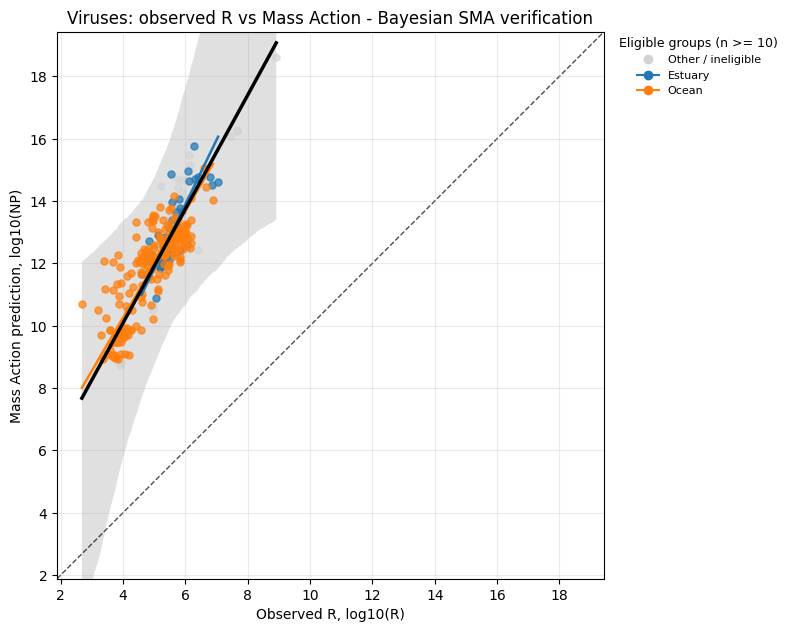

All required columns present in Bayesian SMA input: ['log10R', 'log10poisson_thinning', 'group']
All required columns present in group_eligibility: ['group', 'keep_pt']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10R_vs_log10PT_bayesian_sma.pdf


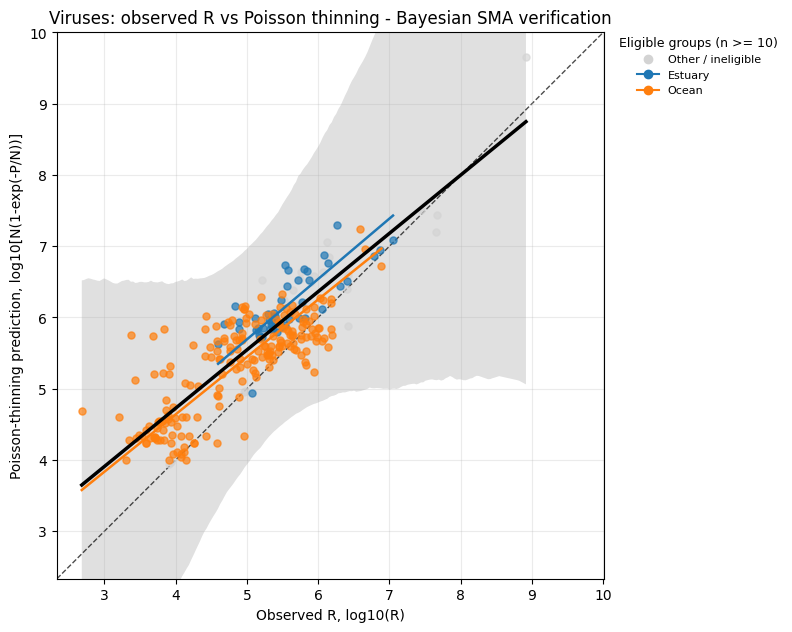

All required columns present in Bayesian SMA input: ['log10mass_action', 'log10reqq', 'group']
All required columns present in group_eligibility: ['group', 'keep_reqq']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10MA_vs_log10reqq_bayesian_sma.pdf


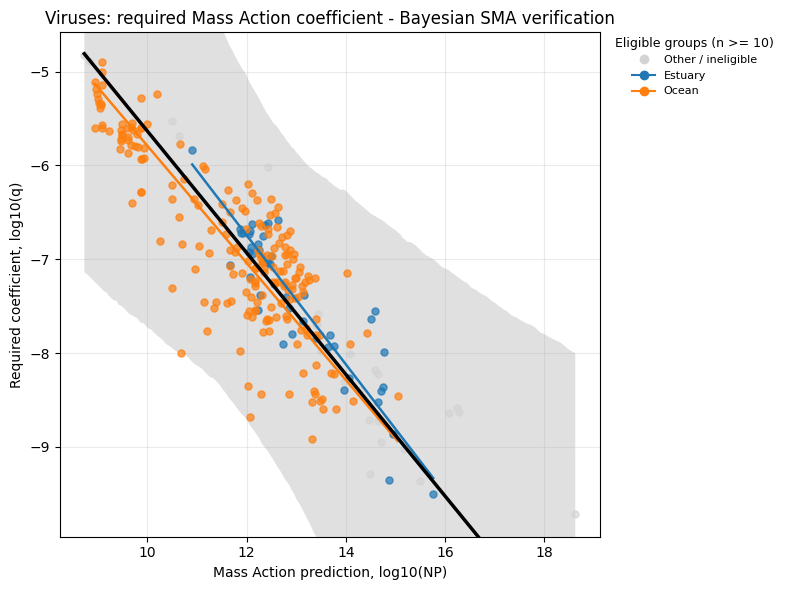

All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10reqz', 'group']
All required columns present in group_eligibility: ['group', 'keep_reqz']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_global_log10PT_vs_log10reqz_bayesian_sma.pdf


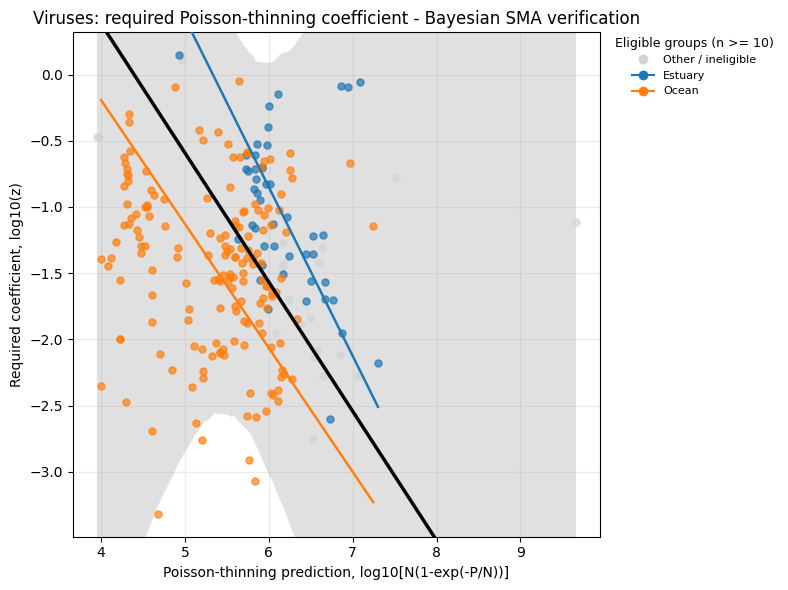

All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10mass_action', 'group']
All required columns present in group_eligibility: ['group', 'keep_mapt']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/results/figures/viruses_log10PT_vs_log10MA_bayesian_sma.pdf


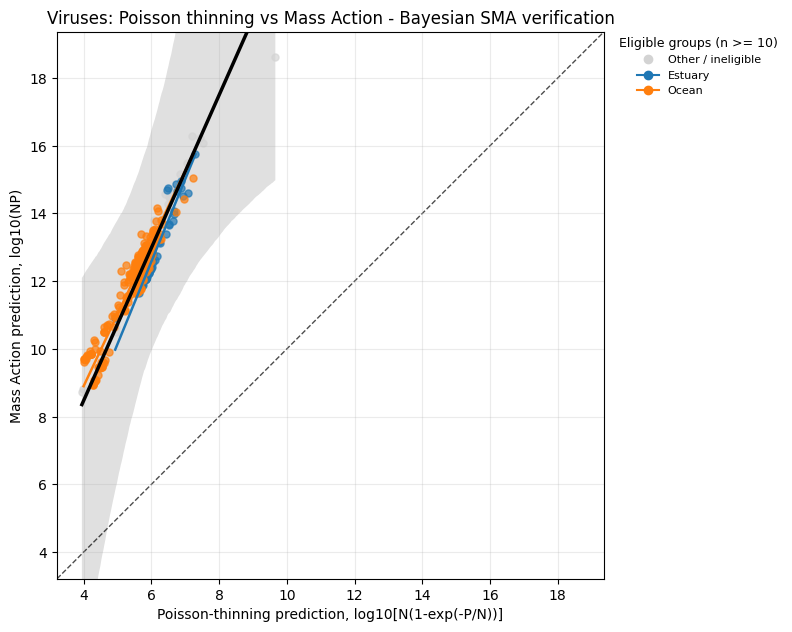

Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Viruses/qc/viruses_plot_manifest.csv


In [17]:
# Cell 17: Bayesian SMA supplementary figures
# Draws posterior line uncertainty and partially pooled group lines without changing primary figures.

def plot_bayesian_sma_analogue(df, model_name, specification, line_stats, idata):
    xcol, ycol = specification["x"], specification["y"]
    sub = prepare_bayesian_fit_data(df, xcol, ycol, group_col=GROUP_COL)
    eligible = set(current_eligible_groups(specification["keep_col"]))
    palette = get_group_palette_from_eligibility(group_eligibility, specification["keep_col"])
    eligible_data = sub.loc[sub[GROUP_COL].isin(eligible)]
    other_data = sub.loc[~sub[GROUP_COL].isin(eligible)]
    figsize = PLOT_STYLE["equal_figsize"] if specification["equal_axes"] else PLOT_STYLE["scatter_figsize"]
    fig, ax = plt.subplots(figsize=figsize)
    if len(other_data):
        ax.scatter(other_data[xcol], other_data[ycol], color="lightgrey",
                   alpha=PLOT_STYLE["other_alpha"], s=PLOT_STYLE["point_size"], zorder=1)
    for group_name, group_data in eligible_data.groupby(GROUP_COL):
        ax.scatter(group_data[xcol], group_data[ycol], color=palette[group_name],
                   alpha=PLOT_STYLE["point_alpha"], s=PLOT_STYLE["point_size"], zorder=2)
    x_values = sub[xcol].to_numpy(dtype=float)
    y_values = sub[ycol].to_numpy(dtype=float)
    x_grid = np.linspace(np.min(x_values), np.max(x_values), 200)
    population = line_stats.loc[
        line_stats["model"].eq(model_name) & line_stats["fit_level"].eq("hierarchical_population")
    ]
    if len(population) == 1 and population.iloc[0]["fit_status"] == "completed" and idata is not None:
        slope_draws = posterior_values(idata, "population_sma_slope")
        intercept_draws = posterior_values(idata, "population_sma_intercept")
        line_draws = intercept_draws[:, None] + slope_draws[:, None] * x_grid[None, :]
        ax.fill_between(x_grid, np.percentile(line_draws, 2.5, axis=0),
                        np.percentile(line_draws, 97.5, axis=0), color="black",
                        alpha=PLOT_STYLE["confidence_alpha"], linewidth=0, zorder=0,
                        label="95% credible band for hierarchical SMA line")
        ax.plot(x_grid, population.iloc[0]["intercept_median"] + population.iloc[0]["slope_median"] * x_grid,
                color="black", lw=PLOT_STYLE["global_linewidth"], zorder=4)
    group_rows = line_stats.loc[
        line_stats["model"].eq(model_name) & line_stats["fit_level"].eq("hierarchical_group")
    ]
    for _, row in group_rows.iterrows():
        group_data = eligible_data.loc[eligible_data[GROUP_COL].eq(row["group_label"])]
        if len(group_data) < 2 or not np.isfinite(row["slope_median"]):
            continue
        group_x = np.linspace(group_data[xcol].min(), group_data[xcol].max(), 100)
        ax.plot(group_x, row["intercept_median"] + row["slope_median"] * group_x,
                color=palette[row["group_label"]], lw=PLOT_STYLE["group_linewidth"], zorder=3)
    if specification["equal_axes"]:
        low, high = padded_limits([min(x_values.min(), y_values.min()), max(x_values.max(), y_values.max())])
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        if specification["unity"]:
            ax.plot([low, high], [low, high], "k--", lw=PLOT_STYLE["unity_linewidth"], alpha=0.70, zorder=0)
        ax.set_aspect("equal", adjustable="box")
    else:
        ax.set_xlim(*padded_limits(x_values))
        ax.set_ylim(*padded_limits(y_values))
    ax.set_xlabel(specification["xlabel"])
    ax.set_ylabel(specification["ylabel"])
    ax.set_title(f"{specification['title']} - Bayesian SMA verification")
    ax.grid(True, alpha=PLOT_STYLE["grid_alpha"])
    add_group_legend(ax, palette, show_other=len(other_data) > 0)
    plt.tight_layout()
    output_path = bayesian_figure_path(specification)
    save_figure(fig, output_path)
    return {"figure": model_name, "figure_type": "supplementary_bayesian_sma", "path": str(output_path)}


if RUN_BAYESIAN:
    selected_bayesian_models = set(bayesian_model_names_to_run())
    for bayesian_model_name, bayesian_plot_specification in MODEL_PLOT_SPECS.items():
        if bayesian_model_name not in selected_bayesian_models:
            continue
        hierarchical_idata = bayesian_idata_by_model.get(bayesian_model_name, {}).get("hierarchical")
        bayesian_plot_manifest_rows.append(plot_bayesian_sma_analogue(
            analysis, bayesian_model_name, bayesian_plot_specification,
            bayesian_line_stats, hierarchical_idata,
        ))
    if bayesian_plot_manifest_rows:
        plot_manifest = pd.concat(
            [plot_manifest, pd.DataFrame(bayesian_plot_manifest_rows)], ignore_index=True
        )
        plot_manifest["exists"] = plot_manifest["path"].map(lambda path: Path(path).exists())
        save_csv(plot_manifest, PLOT_MANIFEST_PATH, index=False)



In [18]:
# Cell 18: Final output manifest
# Keeps primary SMA outputs separate from supplementary Bayesian SMA verification outputs.

print_header("FINAL OUTPUT MANIFEST")

output_manifest = pd.DataFrame([
    {"class": "dataset", "type": "table", "path": str(CANONICAL_HANDOFF_PATH)},
    {"class": "qc", "type": "table", "path": str(CANONICAL_QC_PATH)},
    {"class": "qc", "type": "table", "path": str(CONSTRUCTION_QC_PATH)},
    {"class": "qc", "type": "table", "path": str(REJECTED_NPR_PATH)},
    {"class": "qc", "type": "table", "path": str(GROUP_ELIGIBILITY_PATH)},
    {"class": "qc", "type": "table", "path": str(ANALYSIS_QC_PATH)},
    {"class": "result", "type": "table", "path": str(GLOBAL_FITS_PATH)},
    {"class": "result", "type": "table", "path": str(GROUP_FITS_PATH)},
    {"class": "result", "type": "table", "path": str(FIT_SUMMARY_PATH)},
    {"class": "result", "type": "table", "path": str(DISPLAYED_STATS_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_MA_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_PT_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_REQQ_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_REQZ_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_MAPT_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_MA_PT_MERGED_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_REQQ_REQZ_MERGED_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_CROSSOVER_PATH)},
])

if RUN_BAYESIAN:
    bayesian_output_rows = [
        {"class": "supplementary_bayesian_sma", "type": "table", "path": str(BAYESIAN_LINE_STATS_PATH)},
        {"class": "supplementary_bayesian_sma_qc", "type": "table", "path": str(BAYESIAN_MODEL_DIAGNOSTICS_PATH)},
    ]
    bayesian_output_rows.extend([
        {"class": "supplementary_bayesian_sma", "type": "figure", "path": row["path"]}
        for row in bayesian_plot_manifest_rows
    ])
    output_manifest = pd.concat(
        [output_manifest, pd.DataFrame(bayesian_output_rows)],
        ignore_index=True,
    )

output_manifest["exists"] = output_manifest["path"].map(lambda path: Path(path).exists())
display_df(output_manifest)
save_csv(output_manifest, OUTPUT_MANIFEST_PATH, index=False)



FINAL OUTPUT MANIFEST
                            class    type                                               path  exists
0                         dataset   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
1                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
2                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
3                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
4                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
5                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
6                          result   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
7                          result   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
8                          result   table  /content/drive/MyDrive/Ho

In [19]:
# Cell 19: Optional notebook export helper
# Provides a notebook export helper for Colab sessions.
# Produces exported Python/Markdown/Text copies when the source notebook is available.

print_header("OPTIONAL NOTEBOOK EXPORT")
print("This refactored .py file is the executable source artifact. Notebook export is intentionally not run automatically.")



OPTIONAL NOTEBOOK EXPORT
This refactored .py file is the executable source artifact. Notebook export is intentionally not run automatically.
